# Fashion-IQ Composed Image Retrieval (CIR)

**Architecture:** SigLIP-SO400M (vision + text) fused with always-on ResNet-50 low-level tokens, composition fusion, query residual, and category-aware hard-negative mining.

The target head (`target_aggregator`, `target_fusion`, `target_projector`) trains with the query branch for the first `target_warmup_epochs` epochs, then is frozen: it goes to eval mode, stops receiving gradients, and only the query branch keeps training. With `target_warmup_epochs = 0` the head stays frozen at random init from the start. Positives come from `encode_positive`.

In [1]:
# Cell purpose: Install OpenMP and FAISS (GPU build) for the hard-negative nearest-neighbour search.

!apt install -y libomp-dev
!pip install faiss-gpu-cu12

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libllvm18 libomp-18-dev libomp5-18
Suggested packages:
  libomp-18-doc
The following NEW packages will be installed:
  libllvm18 libomp-18-dev libomp-dev libomp5-18
0 upgraded, 4 newly installed, 0 to remove and 33 not upgraded.
Need to get 29.1 MB of archives.
After this operation, 154 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libllvm18 amd64 1:18.1.3-1ubuntu1 [27.5 MB]
Get:2 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 libomp5-18 amd64 1:18.1.3-1ubuntu1 [608 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 libomp-18-dev amd64 1:18.1.3-1ubuntu1 [968 kB]
Get:4 http://archive.ubuntu.com/ubuntu noble/universe amd64 libomp-dev amd64 1:18.0-59~exp2 [5,366 B]
Fetched 29.1 MB in 0s (83.4 MB/s)
Selecting previously unselected package libllvm

## Reproducibility seed

Fixes Python, NumPy, and PyTorch RNGs and disables cuDNN autotune so training runs are deterministic.

In [2]:
# Cell purpose: Fix the Python, NumPy and PyTorch random seeds and make cuDNN deterministic, for reproducible runs.

import numpy as np
import torch
import random
seed = 43
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Unpack Fashion-IQ

Extracts captions, image splits, and images. Replace the dataset paths before running.

In [3]:
# Cell purpose: Mount Google Drive and unpack the Fashion-IQ captions, image splits and images into /content/data.

## If you are using Google Colab, you can mount your drive to the notebook.

from google.colab import drive
drive.mount('/content/drive')

# If you are using 7zip, you can unzip the dataset here
!apt-get -qq install p7zip-full
!7z x "/content/drive/MyDrive/Colab Notebooks/CIR_Data/fashion-iq.7z" -o/content
!mkdir -p /content/data
!mkdir -p /content/data/images
!mkdir -p /content/data/captions
!mkdir -p /content/data/image_splits
!mkdir -p /content/data/checkpoints
!unzip /content/captions-20220326T130604Z-001.zip -d /content/data
!unzip /content/image_splits-20220326T130551Z-001.zip -d /content/data
!tar -xvzf images.tar.gz -C /content/data

Kết quả truyền trực tuyến bị cắt bớt đến 5000 dòng cuối.
images/B000RJ25T8.png
images/B004R89JYO.png
images/B004N21GJA.png
images/B00BLNL7G6.png
images/B001DYZ4WQ.png
images/B0085SJ492.png
images/B003HF4BTQ.png
images/B004CR6MJK.png
images/B0041O9OYY.png
images/B008941Q7A.png
images/B002ZZDDF2.png
images/B009PPY0UM.png
images/B00BBW5A5Q.png
images/B003TI2IQY.png
images/B009WQRQ64.png
images/B00BUKIMSG.png
images/B00A9SQILI.png
images/B009PKE7M8.png
images/B00CBNK1GW.png
images/B0015CIYSM.png
images/B0090LD3Q8.png
images/B00AR19X1O.png
images/B00FGD89GS.png
images/B005THIVZU.png
images/B008SHUIIQ.png
images/B00CE3C8QK.png
images/B0089YZEGO.png
images/B007V0LBW8.png
images/B003EBNVEO.png
images/B0076IKTVO.png
images/B00CA5TTCI.png
images/B00EA30H56.png
images/B005NY6E4E.png
images/B00AZ2O5XG.png
images/B007CMPTUK.png
images/B0072ZNVSE.png
images/B002EQ9C8O.png
images/B00480MNEE.png
images/B00821UW0C.png
images/B008DS0P7Y.png
images/B00B4NJKPS.png
images/B0058YRWIG.png
images/B005S48LGS.p

## Configuration

Tune these settings against the **dev** split (held out from train), never against val. Val is printed at each eval epoch for monitoring only; the reported result is val on the best dev checkpoint.

In [4]:
# Cell purpose: Define every setting in the Config dataclass (paths, model, losses, training, target-head warmup, dev split, early stopping), then adjust batch size and unfrozen layers to the detected GPU.

from dataclasses import dataclass, field
from typing import List

@dataclass
class Config:
    fashioniq_root: str = '/content/data'
    image_dir: str = '/content/data/images'
    output_dir: str = '/content/data/checkpoints'

    siglip_model_name: str = "google/siglip-so400m-patch14-384"
    embed_dim: int = 512
    num_visual_tokens: int = 160

    resnet_input_size: int = 224
    resnet_extract_layers: List[str] = field(
        default_factory=lambda: ['layer1', "layer2", "layer3"]
    )
    resnet_tokens_per_layer: int = 16
    freeze_resnet_through: str = "layer2"
    lr_resnet: float = 1e-5

    num_fusion_layers: int = 2
    num_fusion_query_tokens: int = 8
    fusion_num_heads: int = 8
    fusion_dropout: float = 0.1
    text_max_length: int = 64

    siglip_vision_unfreeze_layers: int = 2
    lr_siglip_vision: float = 1e-6

    siglip_text_unfreeze_layers: int = 2
    lr_siglip_text: float = 1e-6

    # Train the target head (aggregator, target fusion, target projector) for
    # this many epochs, then freeze it for the rest of training.
    # 0 = frozen at random init from the start.
    target_warmup_epochs: int = 3
    lr_target: float = 1e-4

    num_hard_negatives: int = 24
    num_neg_per_sample: int = 8
    mine_every_n_epochs: int = 1

    target_agg_num_heads: int = 4

    gallery_batch_size: int = 0

    triplet_margin: float = 0.8
    loss_lambda_triplet: float = 2.5
    loss_lambda_contrastive: float = 1.5
    temperature: float = 0.07
    label_smoothing: float = 0.1

    categories: List[str] = field(
        default_factory=lambda: ["dress", "shirt", "toptee"]
    )
    batch_size: int = 24
    num_workers: int = 2
    lr_projector: float = 1e-4
    lr_fusion: float = 1e-4
    weight_decay: float = 0.01
    warmup_ratio: float = 0.08
    num_epochs: int = 25
    grad_accum_steps: int = 4
    max_grad_norm: float = 1.0
    fp16: bool = True
    seed: int = 42

    # Share of train triplets held out as a dev split for checkpoint selection
    # and hyperparameter tuning. Held out as whole connected components of the
    # candidate→target graph, so no dev image appears in training.
    dev_fraction: float = 0.1

    recall_ks: List[int] = field(default_factory=lambda: [10, 50])
    eval_every: int = 2
    # Stop when dev avg R@10 has not improved for this many epochs
    # (checked at each eval, so with eval_every=2 this is 2 evals). 0 = off.
    early_stop_patience: int = 4


cfg = Config()

gpu_mem = torch.cuda.get_device_properties(0).total_memory / 1e9
gpu_name = torch.cuda.get_device_name(0).lower()

if "a100" in gpu_name:
    cfg.batch_size = 40
    cfg.grad_accum_steps = 3
    cfg.siglip_vision_unfreeze_layers = 6
    cfg.siglip_text_unfreeze_layers = 3
    cfg.num_fusion_layers = 4
    cfg.gallery_batch_size = 128
elif "v100" in gpu_name or gpu_mem > 15:
    cfg.batch_size = 12
    cfg.grad_accum_steps = 8
    cfg.siglip_vision_unfreeze_layers = 4
    cfg.siglip_text_unfreeze_layers = 2
    cfg.gallery_batch_size = 80
else:
    cfg.batch_size = 10
    cfg.grad_accum_steps = 10
    cfg.siglip_vision_unfreeze_layers = 3
    cfg.siglip_text_unfreeze_layers = 2
    cfg.gallery_batch_size = 48

if cfg.gallery_batch_size == 0:
    cfg.gallery_batch_size = max(cfg.batch_size * 4, 32)

eff_bs = cfg.batch_size * cfg.grad_accum_steps
print(f"  Model:     {cfg.siglip_model_name}")
print(f"  Query residual: ON")
print(f"  Text augmentation: ON")
print(f"  ResNet-50: layers={cfg.resnet_extract_layers}")
print(f"  Vision unfreeze: last {cfg.siglip_vision_unfreeze_layers} layers")
print(f"  Text unfreeze:   last {cfg.siglip_text_unfreeze_layers} layers")
print(f"  Batch: {cfg.batch_size} × {cfg.grad_accum_steps} = {eff_bs}")
print(f"  Loss: τ={cfg.temperature}, margin={cfg.triplet_margin}, "
      f"λ_trip={cfg.loss_lambda_triplet}, λ_cont={cfg.loss_lambda_contrastive}, "
      f"LS={cfg.label_smoothing}")
print(f"  Gallery batch (inference): {cfg.gallery_batch_size}")
print(f"  Mining: every {cfg.mine_every_n_epochs} epoch ")
print(f"  GPU: {gpu_name} ({gpu_mem:.0f}GB)")

  Model:     google/siglip-so400m-patch14-384
  Query residual: ON
  Text augmentation: ON
  ResNet-50: layers=['layer1', 'layer2', 'layer3']
  Vision unfreeze: last 6 layers
  Text unfreeze:   last 3 layers
  Batch: 40 × 3 = 120
  Loss: τ=0.07, margin=0.8, λ_trip=2.5, λ_cont=1.5, LS=0.1
  Gallery batch (inference): 128
  Mining: every 1 epoch 
  GPU: nvidia a100-sxm4-40gb (42GB)


## Dataset

- **`get_resnet_transform`** — ImageNet-normalized 224×224 transform for the ResNet branch.
- **`FashionIQDataset`** — train/val triplets `(reference, target, captions, category)`. Optionally shuffles/joins the two captions. Returns SigLIP pixels plus ResNet pixels.
- **`FashionIQEvalDataset`** — gallery/eval images only (no captions).
- **`collate_fn`** — stacks a batch of dataset dicts, including ResNet tensors when present.

In [5]:
# Cell purpose: Define the Fashion-IQ datasets: triplets (reference, target, captions) for train/dev/val, gallery images for evaluation, and the batch collate function.

import json
import random
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms as T
from transformers import SiglipProcessor


def get_resnet_transform(input_size: int = 224):
    return T.Compose([
        T.Resize((input_size, input_size)),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406],
                     std=[0.229, 0.224, 0.225]),
    ])


class FashionIQDataset(Dataset):
    def __init__(
        self,
        root_dir: str,
        image_dir: str,
        categories: List[str],
        split: str = "train",
        processor=None,
        resnet_transform=None,
        include_triplet=None,
        text_augment=None,
    ):
        # include_triplet(candidate_id, target_id, category) -> bool keeps a
        # subset of the caption file (used to carve train vs dev).
        self.image_dir = Path(image_dir)
        self.processor = processor
        self.resnet_transform = resnet_transform
        self.text_augment = (split == "train") if text_augment is None \
            else text_augment
        self.triplets = []
        self.base_idx = 0
        for cat in categories:
            cap_file = Path(root_dir) / "captions" / f"cap.{cat}.{split}.json"
            with open(cap_file) as f:
                for ann in json.load(f):
                    if include_triplet is not None and not include_triplet(
                            ann["candidate"], ann["target"], cat):
                        continue
                    self.triplets.append((
                        ann["candidate"], ann["target"],
                        ann["captions"], cat
                    ))

    def _load_image(self, image_id: str) -> Image.Image:
        for ext in [".jpg", ".png", ".jpeg", ""]:
            path = self.image_dir / f"{image_id}{ext}"
            if path.exists():
                return Image.open(path).convert("RGB")
        raise FileNotFoundError(f"Image not found: {image_id}")

    def __len__(self):
        return len(self.triplets)

    def __getitem__(self, idx):
        ref_id, target_id, captions, category = self.triplets[idx]
        ref_image = self._load_image(ref_id)
        target_image = self._load_image(target_id)

        if self.text_augment:
            caps = list(captions)
            if random.random() < 0.5:
                caps = caps[::-1]
            connectors = [". ", " and ", ". Also, ",
                          ". Additionally, ", ", and also "]
            conn = random.choice(connectors)
            if random.random() < 0.1 and len(caps) > 1:
                mod_text = random.choice(caps).strip()
            else:
                mod_text = f"{caps[0].strip()}{conn}{caps[1].strip()}"
        else:
            mod_text = f"{captions[0].strip()}. {captions[1].strip()}"

        ref_inputs = self.processor(images=ref_image, return_tensors="pt")
        target_inputs = self.processor(images=target_image, return_tensors="pt")

        out = {
            "ref_pixel_values": ref_inputs["pixel_values"].squeeze(0),
            "target_pixel_values": target_inputs["pixel_values"].squeeze(0),
            "mod_text": mod_text,
            "ref_id": ref_id,
            "target_id": target_id,
            "category": category,
            "idx": self.base_idx + idx,
        }
        if self.resnet_transform is not None:
            out["ref_resnet_pixels"] = self.resnet_transform(ref_image)
            out["target_resnet_pixels"] = self.resnet_transform(target_image)
        return out


class FashionIQEvalDataset(Dataset):
    def __init__(self, image_dir, image_ids, processor, resnet_transform=None):
        self.image_dir = Path(image_dir)
        self.image_ids = image_ids
        self.processor = processor
        self.resnet_transform = resnet_transform

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        for ext in [".jpg", ".png", ".jpeg", ""]:
            path = self.image_dir / f"{img_id}{ext}"
            if path.exists():
                img = Image.open(path).convert("RGB")
                inputs = self.processor(images=img, return_tensors="pt")
                siglip_px = inputs["pixel_values"].squeeze(0)
                if self.resnet_transform is not None:
                    resnet_px = self.resnet_transform(img)
                    return siglip_px, resnet_px, img_id
                else:
                    return siglip_px, img_id
        raise FileNotFoundError(f"Not found: {img_id}")


def collate_fn(batch):
    out = {
        "ref_pixel_values": torch.stack([s["ref_pixel_values"] for s in batch]),
        "target_pixel_values": torch.stack([s["target_pixel_values"] for s in batch]),
        "mod_texts": [s["mod_text"] for s in batch],
        "ref_ids": [s["ref_id"] for s in batch],
        "target_ids": [s["target_id"] for s in batch],
        "categories": [s["category"] for s in batch],
        "indices": [s["idx"] for s in batch],
    }
    if "ref_resnet_pixels" in batch[0]:
        out["ref_resnet_pixels"] = torch.stack(
            [s["ref_resnet_pixels"] for s in batch])
        out["target_resnet_pixels"] = torch.stack(
            [s["target_resnet_pixels"] for s in batch])
    return out


print(" Dataset (text augmentation + dual preprocessing)")

 Dataset (text augmentation + dual preprocessing)


## Model imports

PyTorch, checkpointing, torchvision ResNet-50, and Hugging Face `SiglipModel` / `AutoProcessor`.

In [6]:
# Cell purpose: Import PyTorch, the torchvision ResNet-50 and the Hugging Face SigLIP model and processor.

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from torchvision.models import resnet50, ResNet50_Weights
from transformers import SiglipModel, AutoProcessor

## `ResNetLowLevelExtractor`

Always-on CNN backbone. Frozen through `freeze_resnet_through` (default `layer2`).

- **`forward`** — spatial tokens from selected layers (`layer1/2/3`).
- **`forward_pooled`** — globally pooled vector via `pool_projector`.
- **`forward_both`** — tokens + pooled in one backbone pass.

`pool_projector` width is the sum of extracted channels (layer1+2+3 → 1792). Checkpoints must match `resnet_extract_layers`.

In [7]:
# Cell purpose: Define the ResNet-50 branch: turns layer1-3 feature maps into tokens and a pooled vector, with the early layers frozen.

class ResNetLowLevelExtractor(nn.Module):
    LAYER_CHANNELS = {
        "layer1": 256, "layer2": 512, "layer3": 1024, "layer4": 2048
    }

    def __init__(self, output_dim, extract_layers=("layer2", "layer3"),
                 tokens_per_layer=16, freeze_through="layer2"):
        super().__init__()
        backbone = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        self.stem = nn.Sequential(
            backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.extract_layers = list(extract_layers)
        self.tokens_per_layer = tokens_per_layer
        pool_side = int(tokens_per_layer ** 0.5)
        assert pool_side * pool_side == tokens_per_layer
        self.adaptive_pool = nn.AdaptiveAvgPool2d((pool_side, pool_side))

        self.token_projectors = nn.ModuleDict({
            name: nn.Sequential(
                nn.LayerNorm(self.LAYER_CHANNELS[name]),
                nn.Linear(self.LAYER_CHANNELS[name], output_dim),
                nn.GELU(),
                nn.Linear(output_dim, output_dim),
            ) for name in extract_layers
        })
        pooled_dim = sum(self.LAYER_CHANNELS[n] for n in extract_layers)
        self.pool_projector = nn.Sequential(
            nn.LayerNorm(pooled_dim),
            nn.Linear(pooled_dim, output_dim),
            nn.GELU(),
        )
        self.pooled_input_dim = pooled_dim
        self._apply_freezing(freeze_through)

    def _apply_freezing(self, freeze_through):
        freeze_order = ["stem", "layer1", "layer2", "layer3", "layer4"]
        if freeze_through not in freeze_order:
            return
        stop = freeze_order.index(freeze_through)
        frozen, total = 0, 0
        for i, name in enumerate(freeze_order):
            for p in getattr(self, name).parameters():
                total += p.numel()
                if i <= stop:
                    p.requires_grad = False
                    frozen += p.numel()
        print(f"   ResNet: froze stem→{freeze_through} "
              f"({frozen/1e6:.1f}M / {total/1e6:.1f}M)")

    def _backbone(self, x):
        feats = {}
        x = self.stem(x)
        x = self.layer1(x)
        if "layer1" in self.extract_layers: feats["layer1"] = x
        x = self.layer2(x)
        if "layer2" in self.extract_layers: feats["layer2"] = x
        x = self.layer3(x)
        if "layer3" in self.extract_layers: feats["layer3"] = x
        if "layer4" in self.extract_layers:
            x = self.layer4(x); feats["layer4"] = x
        return feats

    def _feats_to_tokens(self, feats):
        all_tokens = []
        for name in self.extract_layers:
            fm = self.adaptive_pool(feats[name])
            tokens = fm.flatten(2).permute(0, 2, 1)
            tokens = self.token_projectors[name](tokens)
            all_tokens.append(tokens)
        return torch.cat(all_tokens, dim=1)

    def _feats_to_pooled(self, feats):
        parts = [F.adaptive_avg_pool2d(feats[n], 1).flatten(1)
                 for n in self.extract_layers]
        return self.pool_projector(torch.cat(parts, dim=-1))

    def forward(self, x):
        return self._feats_to_tokens(self._backbone(x))

    def forward_pooled(self, x):
        return self._feats_to_pooled(self._backbone(x))

    def forward_both(self, x):
        feats = self._backbone(x)
        return self._feats_to_tokens(feats), self._feats_to_pooled(feats)

## Visual modules

- **`VisualTokenCompressor`** — cross-attention pooling of SigLIP patches down to `num_visual_tokens`.
- **`MultiScaleVisualMerger`** — concatenates SigLIP and ResNet tokens with type embeddings.
- **`TargetTokenAggregator`** — one learned query over merged tokens → a single target vector. Frozen after `target_warmup_epochs`.
- **`EnhancedTargetFusion`** — gated blend of SigLIP pooled, ResNet pooled, and aggregated tokens. Frozen after `target_warmup_epochs`.
- **`ResidualBlend`** — `composed + gate × reference` with L2 normalize (query residual).
- **`CompositionFusion`** — learned query tokens cross-attend visual + text tokens, then mean-pool.
- **`TargetProjector` / `QueryProjector`** — map fusion dim → `embed_dim` and L2-normalize. The target projector is frozen after `target_warmup_epochs`.

In [8]:
# Cell purpose: Define the visual building blocks: token compressor, SigLIP + ResNet merger, target aggregator and fusion, query residual blend, composition fusion, and the target/query projectors.

class VisualTokenCompressor(nn.Module):
    def __init__(self, dim, num_output_tokens=64, num_heads=8):
        super().__init__()
        self.queries = nn.Parameter(
            torch.randn(1, num_output_tokens, dim) * 0.02)
        self.cross_attn = nn.MultiheadAttention(
            dim, num_heads, batch_first=True)
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4), nn.GELU(), nn.Linear(dim * 4, dim))

    def forward(self, patch_tokens):
        B = patch_tokens.shape[0]
        q = self.queries.expand(B, -1, -1)
        attended, _ = self.cross_attn(q, patch_tokens, patch_tokens)
        x = self.norm1(q + attended)
        return self.norm2(x + self.ffn(x))


class MultiScaleVisualMerger(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.siglip_type = nn.Parameter(torch.zeros(1, 1, dim))
        self.resnet_type = nn.Parameter(torch.zeros(1, 1, dim))
        self.norm = nn.LayerNorm(dim)

    def forward(self, siglip_tokens, resnet_tokens):
        s = siglip_tokens + self.siglip_type
        r = resnet_tokens + self.resnet_type
        return self.norm(torch.cat([s, r], dim=1))


class TargetTokenAggregator(nn.Module):
    def __init__(self, dim, num_heads=4, dropout=0.1):
        super().__init__()
        self.query = nn.Parameter(torch.randn(1, 1, dim) * 0.02)
        self.cross_attn = nn.MultiheadAttention(
            dim, num_heads, batch_first=True, dropout=dropout)
        self.norm1 = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 2), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(dim * 2, dim))
        self.norm2 = nn.LayerNorm(dim)

    def forward(self, tokens):
        B = tokens.shape[0]
        q = self.query.expand(B, -1, -1)
        attended, _ = self.cross_attn(q, tokens, tokens)
        x = self.norm1(q + attended)
        x = self.norm2(x + self.ffn(x))
        return x.squeeze(1)


class EnhancedTargetFusion(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.resnet_gate = nn.Sequential(
            nn.Linear(dim * 2, dim), nn.Sigmoid())
        self.token_gate = nn.Sequential(
            nn.Linear(dim * 2, dim), nn.Sigmoid())
        self.norm = nn.LayerNorm(dim)

    def forward(self, siglip_pooled, resnet_pooled=None,
                token_aggregated=None):
        x = siglip_pooled
        if resnet_pooled is not None:
            g = self.resnet_gate(torch.cat([x, resnet_pooled], dim=-1))
            x = x + g * resnet_pooled
        if token_aggregated is not None:
            g = self.token_gate(torch.cat([x, token_aggregated], dim=-1))
            x = x + g * token_aggregated
        return self.norm(x)


class ResidualBlend(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.gate = nn.Sequential(
            nn.Linear(dim * 2, dim),
            nn.LayerNorm(dim),
            nn.Sigmoid(),
        )
        nn.init.constant_(self.gate[0].bias, -0.85)

    def forward(self, composed, reference):
        alpha = self.gate(torch.cat([composed, reference], dim=-1))
        return F.normalize(composed + alpha * reference, dim=-1)


class CompositionFusion(nn.Module):
    def __init__(self, dim, num_heads=8, num_layers=2,
                 num_query_tokens=8, dropout=0.1):
        super().__init__()
        self.query_tokens = nn.Parameter(
            torch.randn(1, num_query_tokens, dim) * 0.02)
        self.layers = nn.ModuleList()
        for _ in range(num_layers):
            self.layers.append(nn.ModuleList([
                nn.MultiheadAttention(dim, num_heads,
                                      batch_first=True, dropout=dropout),
                nn.LayerNorm(dim),
                nn.Sequential(nn.Linear(dim, dim * 4), nn.GELU(),
                              nn.Dropout(dropout), nn.Linear(dim * 4, dim)),
                nn.LayerNorm(dim),
            ]))
        self.final_norm = nn.LayerNorm(dim)

    def forward(self, visual_tokens, text_tokens, text_attention_mask=None):
        B = visual_tokens.shape[0]
        device = visual_tokens.device
        context = torch.cat([visual_tokens, text_tokens], dim=1)
        if text_attention_mask is not None:
            vis_mask = torch.ones(B, visual_tokens.shape[1],
                                  device=device,
                                  dtype=text_attention_mask.dtype)
            kpm = ~torch.cat([vis_mask, text_attention_mask], dim=1).bool()
        else:
            kpm = None
        x = self.query_tokens.expand(B, -1, -1)
        for cross_attn, n1, ffn, n2 in self.layers:
            att, _ = cross_attn(x, context, context, key_padding_mask=kpm)
            x = n1(x + att)
            x = n2(x + ffn(x))
        return self.final_norm(x.mean(dim=1))


class TargetProjector(nn.Module):
    def __init__(self, dim, embed_dim):
        super().__init__()
        self.proj = nn.Sequential(
            nn.LayerNorm(dim), nn.Linear(dim, embed_dim * 2),
            nn.GELU(), nn.Dropout(0.1), nn.Linear(embed_dim * 2, embed_dim))
    def forward(self, x):
        return F.normalize(self.proj(x), dim=-1)

class QueryProjector(nn.Module):
    def __init__(self, dim, embed_dim):
        super().__init__()
        self.proj = nn.Sequential(
            nn.LayerNorm(dim), nn.Linear(dim, embed_dim * 2),
            nn.GELU(), nn.Dropout(0.1),
            nn.Linear(embed_dim * 2, embed_dim, bias=False))
    def forward(self, x):
        return F.normalize(self.proj(x), dim=-1)

## SigLIP layer helpers

Walk Hugging Face module trees to find encoder layers and pooling heads so freezing/unfreezing works across SigLIP variants.

- `_get_vision_encoder_layers` / `_get_text_encoder_layers`
- `_get_vision_head_params` / `_get_text_head_params`

In [9]:
# Cell purpose: Helpers that find SigLIP's encoder layers and pooling heads, so the last N layers can be unfrozen.

def _get_vision_encoder_layers(vision_model):
    vm = vision_model
    for attr in ["vision_model", "model"]:
        if hasattr(vm, attr):
            vm = getattr(vm, attr); break
    if hasattr(vm, "encoder") and hasattr(vm.encoder, "layers"):
        return vm.encoder.layers
    raise AttributeError(f"Cannot find encoder layers in {type(vision_model)}")

def _get_text_encoder_layers(text_model):
    tm = text_model
    for attr in ["text_model", "model"]:
        if hasattr(tm, attr):
            tm = getattr(tm, attr); break
    if hasattr(tm, "encoder") and hasattr(tm.encoder, "layers"):
        return tm.encoder.layers
    raise AttributeError(f"Cannot find encoder layers in {type(text_model)}")

def _get_vision_head_params(vision_model):
    params = []
    vm = getattr(vision_model, "vision_model",
                 getattr(vision_model, "model", vision_model))
    for attr in ["post_layernorm", "layernorm", "head",
                 "multi_head_attention_pooling_head"]:
        if hasattr(vm, attr):
            params.extend(getattr(vm, attr).parameters())
    return params

def _get_text_head_params(text_model):
    tm = getattr(text_model, "text_model",
                 getattr(text_model, "model", text_model))
    for attr in ["final_layer_norm", "layernorm", "head", "norm"]:
        if hasattr(tm, attr):
            return list(getattr(tm, attr).parameters())
    return []

## `CIRModel`

Main CIR network: SigLIP vision + text, ResNet-50, merger, fusion, projectors, residual blend. The target head trains for the first `target_warmup_epochs` epochs and is then frozen with `set_target_trainable(False)`; while frozen, `train()` keeps it in eval mode.

| Method | Function |
|---|---|
| `_setup_vision_freezing` / `_setup_text_freezing` | Freeze all, unfreeze last N layers + heads |
| `set_target_trainable` | Unfreeze or freeze aggregator, target fusion, and target projector |
| `_extract_siglip_features` | Patch tokens (+ optional compressor) and pooled vector |
| `_extract_text_features` | Tokenize modification text and run the text encoder |
| `_merge_visual` | Concatenate SigLIP and ResNet tokens |
| `encode_target` | Full target embedding, no gradients |
| `encode_target_fast` | Pooled-only target (mining) |
| `encode_positive` | Positive target for the loss: with gradients while the head trains, eval mode and no gradients once frozen |
| `encode_query` | Reference image + text → composed query (+ residual) |
| `get_trainable_param_groups` | AdamW groups: query branch, plus the target head while it is trainable |

In [10]:
# Cell purpose: Define CIRModel: the query encoder (reference image + caption), the target encoder whose head trains for target_warmup_epochs and is then frozen, layer freezing, and the optimizer parameter groups.

class CIRModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg

        print(f"Loading SigLIP: {cfg.siglip_model_name} ")
        base_model = SiglipModel.from_pretrained(cfg.siglip_model_name)
        self.siglip_vision = base_model.vision_model
        self.siglip_text = base_model.text_model

        vision_cfg = base_model.config.vision_config
        text_cfg = base_model.config.text_config
        siglip_dim = vision_cfg.hidden_size
        num_vis_layers = vision_cfg.num_hidden_layers
        num_txt_layers = text_cfg.num_hidden_layers
        ps = vision_cfg.patch_size
        im = vision_cfg.image_size
        if isinstance(im, (list, tuple)):
            im = im[0]
        num_patches = (im // ps) ** 2
        print(f"  dim={siglip_dim}, vis_layers={num_vis_layers}, "
              f"patches={num_patches}, txt_layers={num_txt_layers}")

        self.siglip_processor = AutoProcessor.from_pretrained(
            cfg.siglip_model_name)
        self.tokenizer = self.siglip_processor.tokenizer

        print("Loading ResNet-50")
        self.resnet = ResNetLowLevelExtractor(
            output_dim=siglip_dim,
            extract_layers=cfg.resnet_extract_layers,
            tokens_per_layer=cfg.resnet_tokens_per_layer,
            freeze_through=cfg.freeze_resnet_through)
        num_resnet_tokens = (
            len(cfg.resnet_extract_layers) * cfg.resnet_tokens_per_layer)
        print(f"   ResNet tokens: {num_resnet_tokens}")
        self.visual_merger = MultiScaleVisualMerger(siglip_dim)

        self.target_aggregator = TargetTokenAggregator(
            siglip_dim, num_heads=cfg.target_agg_num_heads,
            dropout=cfg.fusion_dropout)
        print(f"   Target aggregator: 1 query × "
              f"{num_patches + num_resnet_tokens} kv → 1 vec")

        self.target_fusion = EnhancedTargetFusion(siglip_dim)
        print(f"   Target fusion: 3-way gated "
              f"(resnet=True, agg=True)")

        self._setup_vision_freezing(cfg, num_vis_layers)
        self._setup_text_freezing(cfg, num_txt_layers)

        try:
            self.siglip_vision.gradient_checkpointing_enable()
            print("   Grad checkpointing: ON (native)")
        except Exception:
            try:
                vm = getattr(self.siglip_vision, "vision_model",
                             self.siglip_vision)
                vm.encoder.gradient_checkpointing = True
                print("   Grad checkpointing: ON (manual)")
            except Exception as e:
                print(f"     Grad checkpointing failed: {e}")

        self.visual_compressor = VisualTokenCompressor(
            siglip_dim, cfg.num_visual_tokens,
            num_heads=8 if siglip_dim >= 1024 else 4)
        print(f"   Compressor: {num_patches} → "
              f"{cfg.num_visual_tokens} tokens")

        self.fusion = CompositionFusion(
            dim=siglip_dim, num_heads=cfg.fusion_num_heads,
            num_layers=cfg.num_fusion_layers,
            num_query_tokens=cfg.num_fusion_query_tokens,
            dropout=cfg.fusion_dropout)
        total_vis = cfg.num_visual_tokens + num_resnet_tokens
        print(f"   Query fusion: {total_vis} visual + text tokens")

        self.query_projector = QueryProjector(siglip_dim, cfg.embed_dim)
        self.target_projector = TargetProjector(siglip_dim, cfg.embed_dim)

        self.residual_blend = ResidualBlend(cfg.embed_dim)
        # Same modules as the target encoder. Stored as plain attributes so
        # the query residual can name them without registering the weights twice.
        object.__setattr__(self, "reference_fusion", self.target_fusion)
        object.__setattr__(self, "reference_projector", self.target_projector)
        print("   Query residual: ON (detach_ref=True, "
              "reference_fusion + reference_projector)")

        self.target_trainable = False
        self.set_target_trainable(cfg.target_warmup_epochs > 0)

        self._text_templates = [
            "The reference image should be modified: {}",
            "Change the image so that: {}",
            "Modify to: {}",
            "Make these changes: {}",
            "Update the reference: {}",
        ]
        self._default_template = \
            "The reference image should be modified: {}"

        self._print_param_summary()

    def _setup_vision_freezing(self, cfg, num_layers):
        n = cfg.siglip_vision_unfreeze_layers
        for p in self.siglip_vision.parameters():
            p.requires_grad = False
        layers = _get_vision_encoder_layers(self.siglip_vision)
        for i in range(num_layers - n, num_layers):
            for p in layers[i].parameters():
                p.requires_grad = True
        for p in _get_vision_head_params(self.siglip_vision):
            p.requires_grad = True
        uf = sum(p.numel() for p in self.siglip_vision.parameters()
                 if p.requires_grad)
        tot = sum(p.numel() for p in self.siglip_vision.parameters())
        print(f"   SigLIP Vision: unfroze last {n}/{num_layers} "
              f"({uf/1e6:.1f}M / {tot/1e6:.1f}M)")

    def _setup_text_freezing(self, cfg, num_layers):
        n = cfg.siglip_text_unfreeze_layers
        for p in self.siglip_text.parameters():
            p.requires_grad = False
        layers = _get_text_encoder_layers(self.siglip_text)
        for i in range(num_layers - n, num_layers):
            for p in layers[i].parameters():
                p.requires_grad = True
        for p in _get_text_head_params(self.siglip_text):
            p.requires_grad = True
        uf = sum(p.numel() for p in self.siglip_text.parameters()
                 if p.requires_grad)
        tot = sum(p.numel() for p in self.siglip_text.parameters())
        print(f"   SigLIP Text: unfroze last {n}/{num_layers} "
              f"({uf/1e6:.1f}M / {tot/1e6:.1f}M)")

    def _target_modules(self):
        return (self.target_aggregator, self.target_fusion,
                self.target_projector)

    def set_target_trainable(self, trainable):
        """Unfreeze (True) or freeze (False) the target head."""
        self.target_trainable = trainable
        for module in self._target_modules():
            for p in module.parameters():
                p.requires_grad = trainable
                if not trainable:
                    p.grad = None
            module.train(trainable and self.training)
        n = sum(p.numel() for m in self._target_modules()
                for p in m.parameters())
        print(f"   Target head: {'trainable' if trainable else 'frozen'} "
              f"({n/1e6:.2f}M)")

    def train(self, mode=True):
        super().train(mode)
        if mode and not self.target_trainable:
            for module in self._target_modules():
                module.eval()
        return self

    def _print_param_summary(self):
        groups = {
            "SigLIP Vision (frozen)": ([], []),
            "SigLIP Vision (train)":  ([], []),
            "SigLIP Text (frozen)":   ([], []),
            "SigLIP Text (train)":    ([], []),
            "ResNet-50 (frozen)":     ([], []),
            "ResNet-50 (train)":      ([], []),
            "Visual Compressor":      ([], []),
            "Visual Merger":          ([], []),
            "Target Aggregator":      ([], []),
            "Target Fusion":          ([], []),
            "Residual Blend":         ([], []),
            "Fusion Module":          ([], []),
            "Query Projector":        ([], []),
            "Target Projector":       ([], []),
            "Other":                  ([], []),
        }
        for name, p in self.named_parameters():
            if "siglip_vision" in name:
                k = ("SigLIP Vision (train)" if p.requires_grad
                     else "SigLIP Vision (frozen)")
            elif "siglip_text" in name:
                k = ("SigLIP Text (train)" if p.requires_grad
                     else "SigLIP Text (frozen)")
            elif "resnet." in name:
                k = ("ResNet-50 (train)" if p.requires_grad
                     else "ResNet-50 (frozen)")
            elif "visual_compressor" in name: k = "Visual Compressor"
            elif "visual_merger" in name:     k = "Visual Merger"
            elif "target_aggregator" in name: k = "Target Aggregator"
            elif "target_fusion" in name:     k = "Target Fusion"
            elif "residual_blend" in name:    k = "Residual Blend"
            elif "fusion" in name:            k = "Fusion Module"
            elif "query_projector" in name:   k = "Query Projector"
            elif "target_projector" in name:  k = "Target Projector"
            else:                             k = "Other"
            (groups[k][0] if p.requires_grad else groups[k][1]).append(
                p.numel())

        print(f"\n  {'Component':<28} {'Trainable':>12} {'Frozen':>12}")
        print(f"  {'─'*28} {'─'*12} {'─'*12}")
        tt, tf = 0, 0
        for key, (train, frozen) in groups.items():
            t, f_ = sum(train), sum(frozen)
            if t > 0 or f_ > 0:
                print(f"  {key:<28} {t/1e6:>10.2f}M {f_/1e6:>10.2f}M")
            tt += t; tf += f_
        print(f"  {'─'*28} {'─'*12} {'─'*12}")
        print(f"  {'TOTAL':<28} {tt/1e6:>10.2f}M {tf/1e6:>10.2f}M")
        print(f"  Trainable: {tt/1e6:.2f}M ({tt/(tt+tf)*100:.1f}%)\n")
        print(f"  Est. optimizer VRAM: {tt * 16 / 1e9:.2f} GB")

    def _get_pooled(self, model_output, hidden_states):
        if (hasattr(model_output, 'pooler_output')
                and model_output.pooler_output is not None):
            return model_output.pooler_output.float()
        return hidden_states.mean(dim=1)

    def _extract_siglip_features(self, pixel_values, compress=True):
        out = self.siglip_vision(pixel_values=pixel_values)
        patch_tokens = out.last_hidden_state.float()
        pooled = self._get_pooled(out, patch_tokens)
        if compress:
            if self.training:
                patch_tokens = checkpoint(
                    self.visual_compressor, patch_tokens,
                    use_reentrant=False)
            else:
                patch_tokens = self.visual_compressor(patch_tokens)
        return patch_tokens, pooled

    def _extract_text_features(self, texts, device):
        tok = self.tokenizer(
            texts, padding=True, truncation=True,
            max_length=self.cfg.text_max_length,
            return_tensors="pt").to(device)
        out = self.siglip_text(
            input_ids=tok["input_ids"],
            attention_mask=tok.get("attention_mask"))
        return out.last_hidden_state.float(), tok.get("attention_mask")

    def _merge_visual(self, siglip_tokens, resnet_tokens):
        if self.visual_merger is not None and resnet_tokens is not None:
            return self.visual_merger(siglip_tokens, resnet_tokens)
        return siglip_tokens

    @torch.no_grad()
    def encode_target(self, pixel_values, resnet_pixels=None):
        return self._encode_target(pixel_values, resnet_pixels)

    def _encode_target(self, pixel_values, resnet_pixels=None):
        out = self.siglip_vision(pixel_values=pixel_values)
        siglip_patches = out.last_hidden_state.float()
        siglip_pooled = self._get_pooled(out, siglip_patches)

        resnet_pooled, resnet_tokens = None, None
        if resnet_pixels is not None:
            resnet_tokens, resnet_pooled = \
                self.resnet.forward_both(resnet_pixels)

        if resnet_tokens is not None:
            merged = self._merge_visual(siglip_patches, resnet_tokens)
        else:
            merged = siglip_patches
        token_agg = self.target_aggregator(merged)

        fused = self.target_fusion(siglip_pooled, resnet_pooled, token_agg)
        return self.target_projector(fused)

    @torch.no_grad()
    def encode_target_fast(self, pixel_values, resnet_pixels=None):
        out = self.siglip_vision(pixel_values=pixel_values)
        patches = out.last_hidden_state.float()
        siglip_pooled = self._get_pooled(out, patches)

        resnet_pooled = None
        if resnet_pixels is not None:
            resnet_pooled = self.resnet.forward_pooled(resnet_pixels)

        fused = self.target_fusion(siglip_pooled, resnet_pooled, None)
        return self.target_projector(fused)

    def encode_positive(self, pixel_values, resnet_pixels=None):
        if self.target_trainable:
            # Head still training: keep gradients so the loss updates it.
            return self._encode_target(pixel_values, resnet_pixels)
        training = self.training
        self.eval()
        try:
            return self.encode_target(pixel_values, resnet_pixels).detach()
        finally:
            if training:
                self.train()

    def encode_query(self, ref_pixel_values, mod_texts,
                     resnet_pixels=None):
        device = ref_pixel_values.device

        siglip_tokens, siglip_pooled = self._extract_siglip_features(
            ref_pixel_values, compress=True)

        resnet_tokens, resnet_pooled = None, None
        if resnet_pixels is not None:
            resnet_tokens, resnet_pooled = \
                self.resnet.forward_both(resnet_pixels)
        visual_tokens = self._merge_visual(siglip_tokens, resnet_tokens)

        if self.training and hasattr(self, '_text_templates'):
            texts = [random.choice(self._text_templates).format(t)
                     for t in mod_texts]
        else:
            texts = [self._default_template.format(t)
                     for t in mod_texts]
        text_tokens, text_mask = self._extract_text_features(texts, device)

        fused = self.fusion(visual_tokens, text_tokens, text_mask)
        composed_emb = self.query_projector(fused)

        if self.residual_blend is not None:
            ref_fused = self.reference_fusion(
                siglip_pooled, resnet_pooled, None)
            ref_emb = self.reference_projector(ref_fused).detach()
            return self.residual_blend(composed_emb, ref_emb)
        return composed_emb

    def get_trainable_param_groups(self):
        proj_params = list(self.query_projector.parameters())
        proj_params += list(self.visual_compressor.parameters())
        if self.visual_merger is not None:
            proj_params += list(self.visual_merger.parameters())
        proj_params += list(self.residual_blend.parameters())
        proj_params = [p for p in proj_params if p.requires_grad]

        fusion_params = [p for p in self.fusion.parameters()
                         if p.requires_grad]

        resnet_params = [p for p in self.resnet.parameters()
                         if p.requires_grad]

        siglip_vision_params = [
            p for p in self.siglip_vision.parameters() if p.requires_grad]
        siglip_text_params = [
            p for p in self.siglip_text.parameters() if p.requires_grad]

        groups = [
            {"params": proj_params,
             "lr": self.cfg.lr_projector, "weight_decay": 0.01},
            {"params": fusion_params,
             "lr": self.cfg.lr_fusion, "weight_decay": 0.01},
        ]
        # Target head: only while trainable at optimizer creation. After
        # set_target_trainable(False) its grads are None, so AdamW skips it.
        target_params = [p for m in self._target_modules()
                         for p in m.parameters() if p.requires_grad]
        if target_params:
            groups.append({"params": target_params,
                           "lr": self.cfg.lr_target, "weight_decay": 0.01})
        if resnet_params:
            groups.append({"params": resnet_params,
                           "lr": self.cfg.lr_resnet, "weight_decay": 0.01})
        if siglip_vision_params:
            groups.append({"params": siglip_vision_params,
                           "lr": self.cfg.lr_siglip_vision,
                           "weight_decay": 0.01})
        if siglip_text_params:
            groups.append({"params": siglip_text_params,
                           "lr": self.cfg.lr_siglip_text,
                           "weight_decay": 0.01})
        return groups


print(" CIRModel (target head trains for target_warmup_epochs, then frozen)")

 CIRModel (target head trains for target_warmup_epochs, then frozen)


## Embedding cache and hard-negative miner

**`EmbeddingCache`**
- `build` — encode a gallery with `encode_target` or `encode_target_fast`
- `lookup_indices` — gather cached vectors
- `get_numpy_normalized` / `get_category_numpy_normalized` — FAISS-ready L2-normalized arrays

**`HardNegativeMiner`**
- `mine` — dispatches category-aware vs global
- `_mine_category_aware` — FAISS search inside each Fashion-IQ split (dress / shirt / toptee)
- `_mine_global` — search the full train gallery

In [11]:
# Cell purpose: Define the embedding cache over the training gallery and the category-aware FAISS hard-negative miner.

import time
import numpy as np
import faiss
import gc
from torch.cuda.amp import autocast
from tqdm.notebook import tqdm


class EmbeddingCache:
    def __init__(self):
        self.embeddings = None
        self.id_list = []
        self.id2idx = {}
        self.id2cat = {}
        self.cat2indices = {}

    @torch.no_grad()
    def build(self, model, gallery_loader, device,
              id2cat=None):
        print(" Building embedding cache [FAST (pooled-only)]")
        t0 = time.time()
        model.eval()
        all_embs, all_ids = [], []

        encode_fn = model.encode_target_fast

        for batch in tqdm(gallery_loader, desc="Encoding gallery"):
            if len(batch) == 3:
                siglip_px, resnet_px, ids = batch
                resnet_px = resnet_px.to(device)
            else:
                siglip_px, ids = batch
                resnet_px = None

            with autocast():
                emb = encode_fn(siglip_px.to(device), resnet_px)
            all_embs.append(emb.float().cpu())
            if isinstance(ids, torch.Tensor):
                ids = ids.tolist()
            all_ids.extend(ids)

        self.embeddings = torch.cat(all_embs, 0)
        self.id_list = all_ids
        self.id2idx = {iid: i for i, iid in enumerate(all_ids)}

        self.id2cat = id2cat or {}
        self.cat2indices = {}
        if self.id2cat:
            for img_id, idx in self.id2idx.items():
                cat = self.id2cat.get(img_id)
                if cat is not None:
                    self.cat2indices.setdefault(cat, []).append(idx)
            dist = ", ".join(f"{c}={len(v)}"
                             for c, v in sorted(self.cat2indices.items()))
            print(f"   Category distribution: {dist}")

        elapsed = time.time() - t0
        mem_mb = self.embeddings.nelement() * 4 / 1e6
        speed = len(all_ids) / max(elapsed, 0.1)
        print(f" Cached {len(all_ids)} embeddings ({mem_mb:.1f} MB) "
              f"in {elapsed:.1f}s ({speed:.0f} img/s)")
        return self

    def lookup_indices(self, indices):
        return self.embeddings[indices]

    def get_numpy_normalized(self):
        emb_np = self.embeddings.numpy().astype(np.float32).copy()
        faiss.normalize_L2(emb_np)
        return emb_np

    def get_category_numpy_normalized(self, category):
        indices = self.cat2indices.get(category, [])
        if not indices:
            return None, []
        emb = self.embeddings[indices].numpy().astype(np.float32).copy()
        faiss.normalize_L2(emb)
        return emb, indices


class HardNegativeMiner:
    def __init__(self, num_hard_negatives=16, category_aware=True):
        self.num_hard_negatives = num_hard_negatives
        self.category_aware = category_aware

    def mine(self, cache, triplets):
        if self.category_aware and cache.cat2indices:
            return self._mine_category_aware(cache, triplets)
        return self._mine_global(cache, triplets)

    def _mine_category_aware(self, cache, triplets):
        print("  Mining category-aware hard negatives")
        search_k = self.num_hard_negatives + 50
        cat_faiss, cat_local_map = {}, {}

        for cat, cache_idxs in cache.cat2indices.items():
            emb_np, _ = cache.get_category_numpy_normalized(cat)
            if emb_np is None or len(emb_np) == 0:
                continue
            D = emb_np.shape[1]
            index = faiss.IndexFlatIP(D)
            if faiss.get_num_gpus() > 0:
                res = faiss.StandardGpuResources()
                index = faiss.index_cpu_to_gpu(res, 0, index)
            index.add(emb_np)
            cat_faiss[cat] = (index, cache_idxs)
            cat_local_map[cat] = {ci: li for li, ci in enumerate(cache_idxs)}
            print(f"   {cat}: {len(cache_idxs)} items indexed")

        cat_triplets = {}
        for sidx, (rid, tid, _, cat) in enumerate(triplets):
            cat_triplets.setdefault(cat, []).append((sidx, rid, tid))

        hard_neg_map = {}
        for cat, trips in cat_triplets.items():
            if cat not in cat_faiss:
                continue
            faiss_idx, cache_idxs = cat_faiss[cat]
            c2l = cat_local_map[cat]

            target_to_samples = {}
            for sidx, rid, tid in trips:
                target_to_samples.setdefault(tid, []).append((sidx, rid))

            valid_targets, valid_local = [], []
            for tid in target_to_samples:
                ci = cache.id2idx.get(tid)
                if ci is not None and ci in c2l:
                    valid_targets.append(tid)
                    valid_local.append(c2l[ci])

            if not valid_local:
                continue

            emb_np, _ = cache.get_category_numpy_normalized(cat)
            query_vecs = emb_np[valid_local]
            _, nn_local = faiss_idx.search(query_vecs, search_k)

            for i, tid in enumerate(valid_targets):
                exclude_local = set()
                ci_target = cache.id2idx[tid]
                if ci_target in c2l:
                    exclude_local.add(c2l[ci_target])
                for sidx, rid in target_to_samples[tid]:
                    ci_ref = cache.id2idx.get(rid)
                    if ci_ref is not None and ci_ref in c2l:
                        exclude_local.add(c2l[ci_ref])

                negs = []
                for j in range(search_k):
                    li = int(nn_local[i, j])
                    if li >= 0 and li not in exclude_local:
                        negs.append(cache_idxs[li])
                    if len(negs) >= self.num_hard_negatives:
                        break
                if negs:
                    for sidx, _ in target_to_samples[tid]:
                        hard_neg_map[sidx] = negs

        avg_n = (np.mean([len(v) for v in hard_neg_map.values()])
                 if hard_neg_map else 0)
        print(f"⛏️  Mined for {len(hard_neg_map)} samples "
              f"(avg {avg_n:.1f} negs)")
        return hard_neg_map

    def _mine_global(self, cache, triplets):
        print("  Mining hard negatives (global)")
        emb_np = cache.get_numpy_normalized()
        D = emb_np.shape[1]
        index = faiss.IndexFlatIP(D)
        if faiss.get_num_gpus() > 0:
            res = faiss.StandardGpuResources()
            index = faiss.index_cpu_to_gpu(res, 0, index)
        index.add(emb_np)

        search_k = self.num_hard_negatives + 50
        target_to_samples = {}
        for sidx, (rid, tid, _, _) in enumerate(triplets):
            target_to_samples.setdefault(tid, []).append((sidx, rid))

        valid_targets, valid_idxs = [], []
        for tid in target_to_samples:
            if tid in cache.id2idx:
                valid_targets.append(tid)
                valid_idxs.append(cache.id2idx[tid])
        if not valid_idxs:
            return {}

        query_vecs = emb_np[valid_idxs]
        _, nn_indices = index.search(query_vecs, search_k)

        hard_neg_map = {}
        for i, tid in enumerate(valid_targets):
            exclude = {cache.id2idx[tid]}
            for sidx, rid in target_to_samples[tid]:
                if rid in cache.id2idx:
                    exclude.add(cache.id2idx[rid])
            negs = []
            for j in range(search_k):
                ni = int(nn_indices[i, j])
                if ni >= 0 and ni not in exclude:
                    negs.append(ni)
                if len(negs) >= self.num_hard_negatives:
                    break
            if negs:
                for sidx, _ in target_to_samples[tid]:
                    hard_neg_map[sidx] = negs

        avg_n = (np.mean([len(v) for v in hard_neg_map.values()])
                 if hard_neg_map else 0)
        print(f"⛏️  Mined for {len(hard_neg_map)} samples "
              f"(avg {avg_n:.1f} negs)")
        return hard_neg_map


print(" Cache (fast mode + timing) + Category-Aware Miner")

 Cache (fast mode + timing) + Category-Aware Miner


## Losses

- **`HardNegTripletLoss`** — hinge on the hardest `top_k` negatives vs the positive (cosine distance).
- **`BatchContrastiveLoss`** — bidirectional InfoNCE with label smoothing.
- **`CIRLoss`** — `λ_contrastive * contrastive + λ_triplet * triplet`.

In [12]:
# Cell purpose: Define the losses: hard-negative triplet loss, bidirectional InfoNCE contrastive loss, and their weighted sum.

class HardNegTripletLoss(nn.Module):
    def __init__(self, margin=0.3, top_k=8):
        super().__init__()
        self.margin = margin
        self.top_k = top_k

    def forward(self, query, target_pos, neg_embeds, neg_mask):
        d_pos = 1.0 - F.cosine_similarity(query, target_pos, dim=-1)
        d_neg = 1.0 - F.cosine_similarity(
            query.unsqueeze(1).expand_as(neg_embeds), neg_embeds, dim=-1)
        d_neg = d_neg.masked_fill(~neg_mask, float("inf"))

        K = min(self.top_k, d_neg.shape[1])
        d_neg_topk, _ = d_neg.topk(K, dim=1, largest=False)

        d_pos_exp = d_pos.unsqueeze(1).expand_as(d_neg_topk)
        losses = F.relu(d_pos_exp - d_neg_topk + self.margin)

        valid = d_neg_topk < float("inf")
        losses = (losses * valid.float()).sum(1) / \
                 valid.float().sum(1).clamp(min=1)
        return losses.mean()


class BatchContrastiveLoss(nn.Module):
    def __init__(self, temperature=0.07, label_smoothing=0.0):
        super().__init__()
        self.temperature = temperature
        self.label_smoothing = label_smoothing

    def forward(self, query, target):
        sim = query @ target.t() / self.temperature
        B = sim.shape[0]
        labels = torch.arange(B, device=sim.device)

        loss_q2t = F.cross_entropy(
            sim, labels, label_smoothing=self.label_smoothing)
        loss_t2q = F.cross_entropy(
            sim.t(), labels, label_smoothing=self.label_smoothing)

        return (loss_q2t + loss_t2q) / 2.0


class CIRLoss(nn.Module):
    def __init__(self, margin=0.3, temperature=0.07,
                 lam_triplet=1.0, lam_contrastive=1.0,
                 label_smoothing=0.0):
        super().__init__()
        self.triplet = HardNegTripletLoss(margin, top_k=8)
        self.contrastive = BatchContrastiveLoss(
            temperature, label_smoothing)
        self.lam_t = lam_triplet
        self.lam_c = lam_contrastive

    def forward(self, query, target, neg_embeds=None, neg_mask=None):
        l_c = self.contrastive(query, target)
        l_t = torch.tensor(0.0, device=query.device)
        if neg_embeds is not None and neg_mask is not None \
                and neg_mask.any():
            l_t = self.triplet(query, target, neg_embeds, neg_mask)
        total = self.lam_c * l_c + self.lam_t * l_t
        return {"total": total, "contrastive": l_c, "triplet": l_t}


print(" Losses (label smoothing + rebalanced)")

 Losses (label smoothing + rebalanced)


## `evaluate_recall`

Official-style per-category retrieval: encode each category gallery, encode queries, rank by cosine similarity (reference image masked), then report `R@k` per category and `avg_R@k`. Queries whose target is missing from the gallery are counted and reported.

- **`recall_rows`** — one row per category plus `avg`, recall in %.
- **`print_recall_table`** — prints those rows as a table.

In [13]:
# Cell purpose: Define evaluation: per-category Recall@10/50 with the reference image masked, plus the recall table printer.

from torch.cuda.amp import autocast

@torch.no_grad()
def evaluate_recall(model, query_loader, gallery_loaders,
                    recall_ks=[10, 50], device=torch.device("cuda")):
    model.eval()

    gal_embeds, gal_id2idx = {}, {}
    for cat, gl in gallery_loaders.items():
        embs, ids = [], []
        for batch in tqdm(gl, desc=f"Gallery {cat}", leave=False):
            if len(batch) == 3:
                siglip_px, resnet_px, img_ids = batch
                resnet_px = resnet_px.to(device)
            else:
                siglip_px, img_ids = batch
                resnet_px = None

            with autocast():
                embs.append(
                    model.encode_target(
                        siglip_px.to(device), resnet_px
                    ).float().cpu()
                )
            ids.extend(img_ids)
        gal_embeds[cat] = torch.cat(embs, 0)
        gal_id2idx[cat] = {iid: i for i, iid in enumerate(ids)}

    results = {f"{c}_R@{k}": [] for c in gal_embeds for k in recall_ks}
    n_skipped = 0

    for batch in tqdm(query_loader, desc="Eval", leave=False):
        ref_px = batch["ref_pixel_values"].to(device)
        resnet_px = batch.get("ref_resnet_pixels")
        if resnet_px is not None:
            resnet_px = resnet_px.to(device)

        with autocast():
            q = model.encode_query(
                ref_px, batch["mod_texts"], resnet_px
            ).float().cpu()

        for i in range(len(batch["target_ids"])):
            cat = batch["categories"][i]
            tid = batch["target_ids"][i]
            if tid not in gal_id2idx[cat]:
                n_skipped += 1
                continue
            sims = F.cosine_similarity(q[i:i+1], gal_embeds[cat], dim=-1)
            ref_id = batch["ref_ids"][i]
            if ref_id in gal_id2idx[cat]:
                sims[gal_id2idx[cat][ref_id]] = -1e9

            _, ranked = sims.sort(descending=True)
            rank = (ranked == gal_id2idx[cat][tid]).nonzero(as_tuple=True)[0].item()
            for k in recall_ks:
                results[f"{cat}_R@{k}"].append(1.0 if rank < k else 0.0)

    if n_skipped:
        print(f"  WARNING: {n_skipped} queries skipped (target not in "
              f"gallery); recall is computed without them")

    metrics = {}
    for key, vals in results.items():
        if vals:
            metrics[key] = np.mean(vals)
    for k in recall_ks:
        scores = [metrics.get(f"{c}_R@{k}", 0) for c in gal_embeds]
        metrics[f"avg_R@{k}"] = np.mean(scores)
    return metrics


def recall_rows(metrics, categories, recall_ks):
    """One row per category plus the category average, recall in %."""
    return [
        {"category": cat,
         **{f"R@{k}": round(100 * metrics.get(f"{cat}_R@{k}", float("nan")), 2)
            for k in recall_ks}}
        for cat in list(categories) + ["avg"]
    ]


def print_recall_table(metrics, categories, recall_ks, title):
    """Per-category R@k and their average across categories (%)."""
    cols = [f"R@{k}" for k in recall_ks]
    print(f"  {title}")
    print(f"    {'category':<10}" + "".join(f"{c:>9}" for c in cols))
    for row in recall_rows(metrics, categories, recall_ks):
        print(f"    {row['category']:<10}"
              + "".join(f"{row[c]:>9.2f}" for c in cols))


print(" Evaluation (dual-pixel aware)")

 Evaluation (dual-pixel aware)


## Training utilities

- **`set_seed`** — RNG helper used at train start.
- **`CategoryBatchSampler`** — each mini-batch is a single category (dress / shirt / toptee).
- **`build_id2cat_mapping`** — image id → category from split JSON.
- **`build_dev_split`** — holds out about `dev_fraction` of train triplets as a dev split, as whole connected components, so no dev image appears in training.
- **`build_gallery_loaders`** — one eval DataLoader per category (from a split file, or from explicit ids for dev).
- **`build_full_gallery_loader`** — union gallery for mining, minus excluded (dev) images.
- **`get_neg_embeddings_for_batch`** — pull mined negatives from the cache.
- **`write_training_log`** — rewrites a CSV log from a list of row dicts.
- **`plot_training`** — train loss, dev/val recall, triplet diagnostics, and LR curves.

In [14]:
# Cell purpose: Training utilities: seeding, single-category batch sampler, dev split, gallery loaders, negative lookup, CSV log writer and training plots.

import matplotlib.pyplot as plt
from IPython.display import clear_output


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


class CategoryBatchSampler(torch.utils.data.Sampler):
    def __init__(self, concat_dataset, categories, batch_size,
                 drop_last=True):
        self.batch_size = batch_size
        self.drop_last = drop_last
        self.cat_indices = {}
        offset = 0
        for ds, cat in zip(concat_dataset.datasets, categories):
            self.cat_indices.setdefault(cat, []).extend(
                range(offset, offset + len(ds)))
            offset += len(ds)
        for cat, idxs in self.cat_indices.items():
            n_batches = len(idxs) // batch_size if drop_last \
                        else (len(idxs) + batch_size - 1) // batch_size
            print(f"   {cat}: {len(idxs)} samples → {n_batches} batches")

    def __iter__(self):
        all_batches = []
        for cat, indices in self.cat_indices.items():
            shuffled = indices.copy()
            random.shuffle(shuffled)
            for i in range(0, len(shuffled), self.batch_size):
                batch = shuffled[i : i + self.batch_size]
                if len(batch) == self.batch_size:
                    all_batches.append(batch)
                elif not self.drop_last:
                    all_batches.append(batch)
        random.shuffle(all_batches)
        for batch in all_batches:
            yield batch

    def __len__(self):
        total = 0
        for indices in self.cat_indices.values():
            n = len(indices)
            if self.drop_last:
                total += n // self.batch_size
            else:
                total += (n + self.batch_size - 1) // self.batch_size
        return total


def build_id2cat_mapping(cfg, split="train"):
    id2cat = {}
    for cat in cfg.categories:
        path = (f"{cfg.fashioniq_root}/image_splits/"
                f"split.{cat}.{split}.json")
        with open(path) as f:
            for img_id in json.load(f):
                id2cat[img_id] = cat
    print(f"   id2cat: {len(id2cat)} images across "
          f"{len(cfg.categories)} categories ({split})")
    return id2cat


def build_dev_split(cfg):
    """Hold out a dev split from train with no image shared with training.

    Triplets are grouped into connected components of the candidate→target
    graph, per category. Whole components go to dev until it holds about
    `dev_fraction` of the triplets, so every dev image (reference or target)
    is unseen in training and no train triplet is dropped. A matching share
    of train-split images that appear in no triplet joins the dev gallery as
    distractors and is removed from the mining gallery.

    Returns {category: set of dev image ids}.
    """
    rng = random.Random(cfg.seed)
    dev_images = {}
    for cat in cfg.categories:
        with open(f"{cfg.fashioniq_root}/captions/cap.{cat}.train.json") as f:
            anns = json.load(f)
        with open(f"{cfg.fashioniq_root}/image_splits/"
                  f"split.{cat}.train.json") as f:
            split_ids = json.load(f)

        parent = {}
        def find(x):
            parent.setdefault(x, x)
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x
        for ann in anns:
            ra, rb = find(ann["candidate"]), find(ann["target"])
            if ra != rb:
                parent[ra] = rb

        comp_triplets, comp_images = {}, {}
        for ann in anns:
            root = find(ann["candidate"])
            comp_triplets[root] = comp_triplets.get(root, 0) + 1
            comp_images.setdefault(root, set()).update(
                (ann["candidate"], ann["target"]))

        roots = sorted(comp_triplets)
        rng.shuffle(roots)
        goal = cfg.dev_fraction * len(anns)
        # Never move one oversized component into dev.
        max_comp = max(1, int(0.02 * len(anns)))
        dev, n_dev = set(), 0
        for root in roots:
            if n_dev >= goal:
                break
            if comp_triplets[root] > max_comp:
                continue
            dev |= comp_images[root]
            n_dev += comp_triplets[root]

        used = set().union(*comp_images.values()) if comp_images else set()
        unused = sorted(set(split_ids) - used)
        rng.shuffle(unused)
        dev.update(unused[:int(cfg.dev_fraction * len(unused))])

        dev_images[cat] = dev
        print(f"   dev {cat}: {n_dev}/{len(anns)} triplets, "
              f"{len(dev)} gallery images "
              f"(largest component {max(comp_triplets.values())} triplets)")
    return dev_images


def build_gallery_loaders(cfg, processor, resnet_transform, split="val",
                          ids_by_cat=None):
    # ids_by_cat overrides the split files (used for the dev gallery).
    gbs = cfg.gallery_batch_size
    loaders = {}
    for cat in cfg.categories:
        if ids_by_cat is not None:
            ids = sorted(ids_by_cat[cat])
        else:
            with open(f"{cfg.fashioniq_root}/image_splits/"
                      f"split.{cat}.{split}.json") as f:
                ids = json.load(f)
        ds = FashionIQEvalDataset(
            cfg.image_dir, ids, processor,
            resnet_transform=resnet_transform)
        loaders[cat] = DataLoader(
            ds, batch_size=gbs, shuffle=False,
            num_workers=cfg.num_workers, pin_memory=True,
            persistent_workers=True if cfg.num_workers > 0 else False)
    return loaders


def build_full_gallery_loader(cfg, processor, resnet_transform,
                               split="train", exclude=None):
    # exclude: image ids kept out of the mining gallery (the dev images), so
    # they never become hard negatives in training.
    gbs = cfg.gallery_batch_size
    all_ids = set()
    for cat in cfg.categories:
        with open(f"{cfg.fashioniq_root}/image_splits/"
                  f"split.{cat}.{split}.json") as f:
            all_ids.update(json.load(f))
    if exclude:
        all_ids -= exclude
    ds = FashionIQEvalDataset(
        cfg.image_dir, sorted(all_ids), processor,
        resnet_transform=resnet_transform)
    n_batches = (len(ds) + gbs - 1) // gbs
    print(f"   Gallery loader: {len(ds)} imgs, bs={gbs}, "
          f"~{n_batches} batches")
    return DataLoader(
        ds, batch_size=gbs, shuffle=False,
        num_workers=cfg.num_workers, pin_memory=True,
        persistent_workers=True if cfg.num_workers > 0 else False)


def get_neg_embeddings_for_batch(batch_indices, hard_neg_map, cache,
                                  num_negs=4,
                                  device=torch.device("cuda")):
    B = len(batch_indices)
    D = cache.embeddings.shape[1]
    K = num_negs
    neg_embeds = torch.zeros(B, K, D)
    neg_mask = torch.zeros(B, K, dtype=torch.bool)
    for i, sample_idx in enumerate(batch_indices):
        if sample_idx in hard_neg_map:
            neg_cache_idxs = hard_neg_map[sample_idx]
            if len(neg_cache_idxs) > K:
                neg_cache_idxs = neg_cache_idxs[:K]
            k = len(neg_cache_idxs)
            neg_embeds[i, :k] = cache.lookup_indices(neg_cache_idxs)
            neg_mask[i, :k] = True
    return neg_embeds.to(device), neg_mask.to(device)


def write_training_log(rows, path):
    """Rewrite the per-epoch CSV log so it survives a cleared notebook."""
    import csv
    fields = []
    for row in rows:
        for key in row:
            if key not in fields:
                fields.append(key)
    with open(path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


def plot_training(history):
    epochs = range(1, len(history["loss"]) + 1)
    fig, axes = plt.subplots(1, 4, figsize=(24, 4))
    # Left axis: total and contrastive. Right axis: triplet, which is ~100x
    # smaller and would be a flat line on the shared scale.
    axes[0].plot(epochs, history["loss"], color="C0", label="total")
    axes[0].plot(epochs, history["contrastive"], color="C1", alpha=0.7,
                 label="contrastive")
    axes[0].set_ylabel("total / contrastive")
    ax_trip = axes[0].twinx()
    ax_trip.plot(epochs, history["triplet"], color="C2", alpha=0.8,
                 label="triplet (right axis)")
    ax_trip.set_ylabel("triplet", color="C2")
    ax_trip.tick_params(axis="y", colors="C2")
    lines = axes[0].get_lines() + ax_trip.get_lines()
    axes[0].legend(lines, [l.get_label() for l in lines])
    axes[0].set_title("Train loss"); axes[0].set_xlabel("epoch")
    axes[0].grid(True)
    if history["val_R@10"]:
        axes[1].plot(history["eval_epochs"], history["val_R@10"], "o-",
                     color="C0", label="val avg R@10")
        axes[1].plot(history["eval_epochs"], history["val_R@50"], "s-",
                     color="C1", label="val avg R@50")
        axes[1].set_title("Val recall (monitoring only)")
        axes[1].set_xlabel("epoch")
        axes[1].legend(); axes[1].grid(True)
    axes[2].plot(epochs, history["cos_pos"], label="cos(query, positive)")
    axes[2].plot(epochs, history["cos_neg"], label="cos(query, mined neg)")
    axes[2].plot(epochs, history["active_triplets"],
                 label="share of triplets with loss > 0")
    axes[2].set_title("Triplet diagnostics"); axes[2].set_xlabel("epoch")
    axes[2].legend(); axes[2].grid(True)
    if history["lr"]:
        axes[3].plot(epochs, history["lr"]); axes[3].set_title("LR (group 0)")
        axes[3].set_xlabel("epoch")
        axes[3].set_yscale("log"); axes[3].grid(True)
    plt.tight_layout(); plt.show()


print(" Utilities (fast gallery + CategoryBatchSampler)")

 Utilities (fast gallery + CategoryBatchSampler)


## Build model, data, optimizer, scheduler

Constructs `CIRModel`, `CIRLoss`, AdamW on the query branch (plus the target head when `target_warmup_epochs > 0`), GradScaler, the dev split, train loaders with `CategoryBatchSampler`, dev and val loaders and galleries, the mining gallery (dev images excluded), `EmbeddingCache`, cosine LR with warmup (`lr_lambda`), and the history and CSV log paths.

In [15]:
# Cell purpose: Build the model, loss, optimizer, dev split, train/dev/val loaders, mining gallery and LR schedule, and set up the history and log files.

from torch.cuda.amp import autocast, GradScaler

set_seed(cfg.seed)
device = torch.device("cuda")

model = CIRModel(cfg).to(device)
processor = model.siglip_processor
resnet_tf = get_resnet_transform(cfg.resnet_input_size)

criterion = CIRLoss(
    margin=cfg.triplet_margin, temperature=cfg.temperature,
    lam_triplet=cfg.loss_lambda_triplet,
    lam_contrastive=cfg.loss_lambda_contrastive,
    label_smoothing=cfg.label_smoothing,
)

optimizer = torch.optim.AdamW(
    model.get_trainable_param_groups(), weight_decay=cfg.weight_decay)
scaler = GradScaler() if cfg.fp16 else None

print("Loading datasets")
print("Carving dev split from train (checkpoint selection + tuning):")
dev_images = build_dev_split(cfg)
all_dev_images = set().union(*dev_images.values())

def _is_dev(ref_id, target_id, cat):
    # Components are all-in or all-out, so both ids agree; check both anyway.
    return ref_id in dev_images[cat] and target_id in dev_images[cat]

def _is_train(ref_id, target_id, cat):
    return (ref_id not in dev_images[cat]
            and target_id not in dev_images[cat])

train_datasets = [
    FashionIQDataset(
        cfg.fashioniq_root, cfg.image_dir, [cat], "train",
        processor, resnet_transform=resnet_tf,
        include_triplet=_is_train,
    )
    for cat in cfg.categories
]
train_dataset = ConcatDataset(train_datasets)
offset = 0
for ds in train_datasets:
    ds.base_idx = offset
    offset += len(ds)

all_triplets = []
for ds in train_datasets:
    all_triplets.extend(ds.triplets)

print(f"\nCategory batch sampler (batch_size={cfg.batch_size}):")
cat_sampler = CategoryBatchSampler(
    train_dataset, cfg.categories,
    batch_size=cfg.batch_size, drop_last=True)

train_loader = DataLoader(
    train_dataset, batch_sampler=cat_sampler,
    num_workers=cfg.num_workers, pin_memory=True,
    collate_fn=collate_fn)

# Dev queries: train captions whose images were all held out. Fixed caption
# join (no augmentation), same as val.
dev_datasets = [
    FashionIQDataset(
        cfg.fashioniq_root, cfg.image_dir, [cat], "train",
        processor, resnet_transform=resnet_tf,
        include_triplet=_is_dev, text_augment=False)
    for cat in cfg.categories
]
dev_loader = DataLoader(
    ConcatDataset(dev_datasets), batch_size=cfg.batch_size,
    shuffle=False, num_workers=cfg.num_workers,
    pin_memory=True, collate_fn=collate_fn)
dev_gal_loaders = build_gallery_loaders(
    cfg, processor, resnet_tf, ids_by_cat=dev_images)

# Val is scored at each eval epoch for monitoring only. Checkpoint selection
# and early stopping use dev; never change settings because of val numbers.
val_datasets = [
    FashionIQDataset(
        cfg.fashioniq_root, cfg.image_dir, [cat], "val",
        processor, resnet_transform=resnet_tf,
    )
    for cat in cfg.categories
]
val_loader = DataLoader(
    ConcatDataset(val_datasets), batch_size=cfg.batch_size,
    shuffle=False, num_workers=cfg.num_workers,
    pin_memory=True, collate_fn=collate_fn)
val_gal_loaders = build_gallery_loaders(cfg, processor, resnet_tf, "val")

miner = HardNegativeMiner(
    cfg.num_hard_negatives, category_aware=True)
mining_gallery_loader = build_full_gallery_loader(
    cfg, processor, resnet_tf, "train", exclude=all_dev_images)
train_id2cat = build_id2cat_mapping(cfg, split="train")

embed_cache = EmbeddingCache()
hard_neg_map = {}

total_steps = ((len(train_loader) + cfg.grad_accum_steps - 1)
               // cfg.grad_accum_steps) * cfg.num_epochs
warmup_steps = int(total_steps * cfg.warmup_ratio)

def lr_lambda(step):
    if step < warmup_steps:
        return step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return max(0.01, 0.5 * (1 + np.cos(np.pi * progress)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

history = {"loss": [], "contrastive": [], "triplet": [],
           "cos_pos": [], "cos_neg": [], "active_triplets": [],
           "R@10": [], "R@50": [], "val_R@10": [], "val_R@50": [],
           "eval_epochs": [], "lr": []}
log_rows = []
log_path = f"{cfg.output_dir}/training_log.csv"
# Val per eval epoch: epoch, category (dress/shirt/toptee/avg), R@10, R@50 (%)
val_epoch_rows = []
val_epoch_log_path = f"{cfg.output_dir}/val_by_epoch.csv"

best_recall = 0.0
best_epoch = 0
global_step = 0

Loading SigLIP: google/siglip-so400m-patch14-384 


config.json:   0%|          | 0.00/576 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.51GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

... (8 outputs left out)

100%|██████████| 97.8M/97.8M [00:00<00:00, 235MB/s]


   ResNet: froze stem→layer2 (1.4M / 23.5M)
   ResNet tokens: 48
   Target aggregator: 1 query × 777 kv → 1 vec
   Target fusion: 3-way gated (resnet=True, agg=True)
   SigLIP Vision: unfroze last 6/27 (106.7M / 428.2M)
   SigLIP Text: unfroze last 3/27 (45.7M / 449.7M)
   Grad checkpointing: ON (native)
   Compressor: 729 → 160 tokens
   Query fusion: 208 visual + text tokens
   Query residual: ON (detach_ref=True, reference_fusion + reference_projector)
   Target head: trainable (17.65M)

  Component                       Trainable       Frozen
  ──────────────────────────── ──────────── ────────────
  SigLIP Vision (frozen)             0.00M     321.55M
  SigLIP Vision (train)            106.68M       0.00M
  SigLIP Text (frozen)               0.00M     404.01M
  SigLIP Text (train)               45.72M       0.00M
  ResNet-50 (frozen)                 0.00M       1.44M
  ResNet-50 (train)                 30.19M       0.00M
  Visual Compressor                 16.12M       0.00M
  Vis

/tmp/ipykernel_568/10975086.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() if cfg.fp16 else None


Loading datasets
Carving dev split from train (checkpoint selection + tuning):
   dev dress: 609/5985 triplets, 1156 gallery images (largest component 38 triplets)
   dev shirt: 603/5988 triplets, 1900 gallery images (largest component 22 triplets)
   dev toptee: 605/6027 triplets, 1613 gallery images (largest component 35 triplets)

Category batch sampler (batch_size=40):
   dress: 5376 samples → 134 batches
   shirt: 5385 samples → 134 batches
   toptee: 5422 samples → 135 batches
   Gallery loader: 40766 imgs, bs=128, ~319 batches
   id2cat: 45429 images across 3 categories (train)


## Training loop

For each epoch:

1. At the start of epoch `target_warmup_epochs + 1`, freeze the target head (`set_target_trainable(False)`). Before that it trains with the query branch.
2. Rebuild the embedding cache and mine hard negatives every `mine_every_n_epochs`.
3. Train with mixed precision, grad accumulation, and clipped grads. Positives use `encode_positive`, which keeps gradients only while the head is trainable.
4. Every `eval_every` epochs (and the last epoch), run `evaluate_recall` on the **dev** split, print R@10 / R@50 per category with their averages, and save `best_model.pt` when dev avg R@10 improves. Val is also scored and logged to `val_by_epoch.csv` for monitoring; it never picks the checkpoint or triggers early stopping.
5. Stop early when dev avg R@10 has not improved for `early_stop_patience` epochs.
6. Log each epoch (losses, triplet diagnostics, LR, dev recall) to `training_log.csv` in `output_dir`, and plot curves every 5 epochs.

Training: 25 epochs
   Category batching + residual query
   Target head: trains for 3 epochs, then frozen
  Batches/epoch: 403
  Effective BS: 40 × 3 = 120
  Steps: 3375, warmup: 270
  Mining: every 1 epoch, fast=True
  Early stopping: patience 4 epochs on dev avg R@10
  Log: /content/data/checkpoints/training_log.csv
 Building embedding cache [FAST (pooled-only)]


Encoding gallery:   0%|          | 0/319 [00:00<?, ?it/s]

/tmp/ipykernel_568/4217395453.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


   Category distribution: dress=10296, shirt=16058, toptee=14412
 Cached 40766 embeddings (83.5 MB) in 267.3s (153 img/s)
  Mining category-aware hard negatives
   shirt: 16058 items indexed
   dress: 10296 items indexed
   toptee: 14412 items indexed
⛏️  Mined for 15814 samples (avg 24.0 negs)
   RAM: 7.0/89.6 GB (11.2%)


Epoch 1/25:   0%|          | 0/403 [00:00<?, ?it/s]

/tmp/ipykernel_568/2975889587.py:73: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_568/2975889587.py:73: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


... (36 outputs left out)

Encoding gallery:   0%|          | 0/319 [00:00<?, ?it/s]

   Category distribution: dress=10296, shirt=16058, toptee=14412
 Cached 40766 embeddings (83.5 MB) in 263.7s (155 img/s)
  Mining category-aware hard negatives
   shirt: 16058 items indexed
   dress: 10296 items indexed
   toptee: 14412 items indexed
⛏️  Mined for 15814 samples (avg 24.0 negs)
   RAM: 10.1/89.6 GB (15.8%)


Epoch 5/25:   0%|          | 0/403 [00:00<?, ?it/s]

  Epoch 5/25 | loss=3.2463 | cont=1.4061 | trip=0.4549 | lr=9.59e-05
    cos(q,pos)=0.6720 | cos(q,neg)=0.3376 | triplets with loss>0: 100.0% | batches: dress=134 | shirt=134 | toptee=135


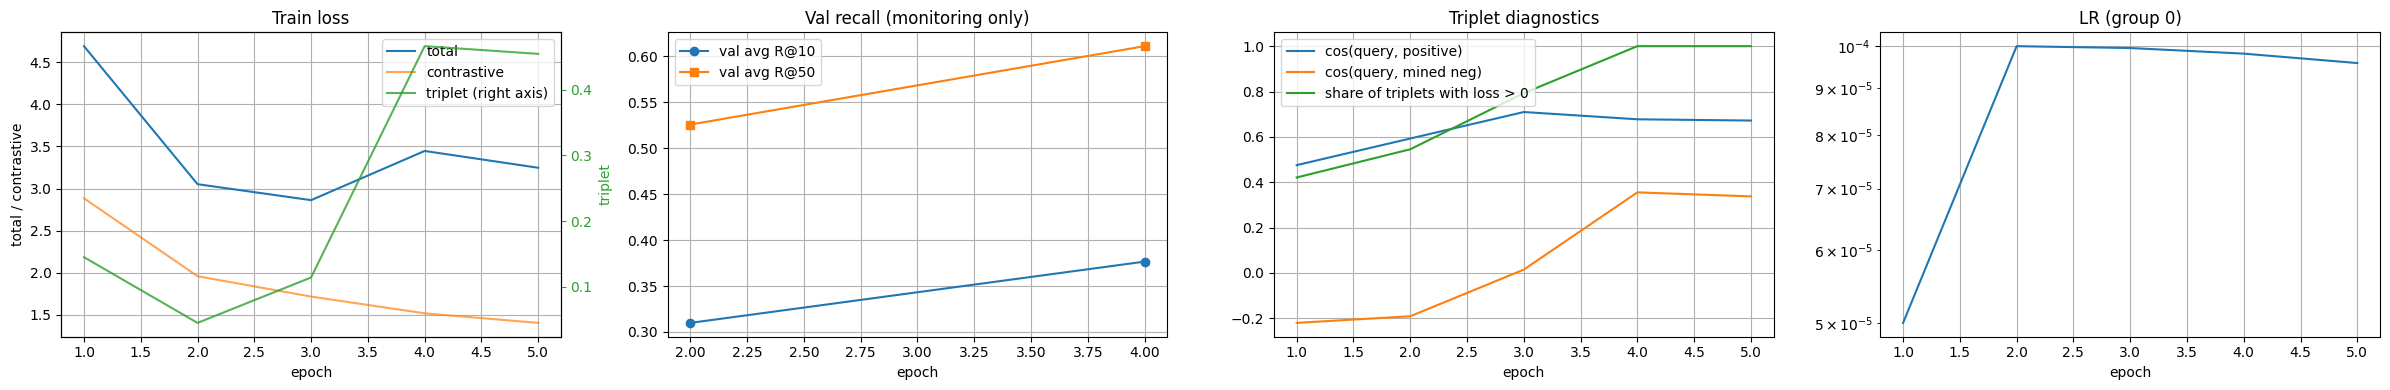

 Building embedding cache [FAST (pooled-only)]


Encoding gallery:   0%|          | 0/319 [00:00<?, ?it/s]

   Category distribution: dress=10296, shirt=16058, toptee=14412
 Cached 40766 embeddings (83.5 MB) in 263.8s (155 img/s)
  Mining category-aware hard negatives
   shirt: 16058 items indexed
   dress: 10296 items indexed
   toptee: 14412 items indexed
⛏️  Mined for 15814 samples (avg 24.0 negs)
   RAM: 10.1/89.6 GB (15.8%)


Epoch 6/25:   0%|          | 0/403 [00:00<?, ?it/s]

  Epoch 6/25 | loss=3.0940 | cont=1.3106 | trip=0.4513 | lr=9.27e-05
    cos(q,pos)=0.6746 | cos(q,neg)=0.3363 | triplets with loss>0: 100.0% | batches: dress=134 | shirt=134 | toptee=135


Gallery dress:   0%|          | 0/10 [00:00<?, ?it/s]

... (41 outputs left out)

Gallery shirt:   0%|          | 0/50 [00:00<?, ?it/s]

Gallery toptee:   0%|          | 0/42 [00:00<?, ?it/s]

Eval:   0%|          | 0/151 [00:00<?, ?it/s]

  VAL epoch 10 (monitoring only), %
    category       R@10     R@50
    dress         33.81    58.45
    shirt         36.21    58.05
    toptee        41.61    65.53
    avg           37.21    60.68


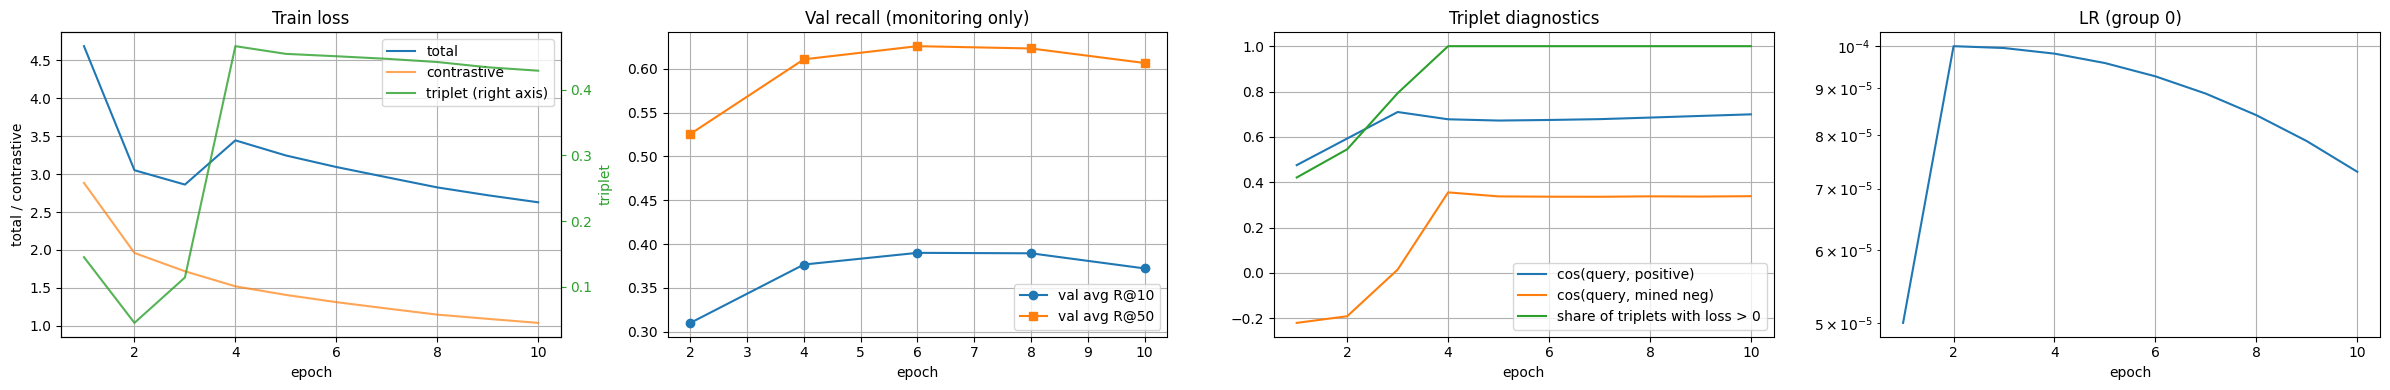

 Building embedding cache [FAST (pooled-only)]


Encoding gallery:   0%|          | 0/319 [00:00<?, ?it/s]

   Category distribution: dress=10296, shirt=16058, toptee=14412
 Cached 40766 embeddings (83.5 MB) in 263.5s (155 img/s)
  Mining category-aware hard negatives
   shirt: 16058 items indexed
   dress: 10296 items indexed
   toptee: 14412 items indexed
⛏️  Mined for 15814 samples (avg 24.0 negs)
   RAM: 9.9/89.6 GB (15.6%)


Epoch 11/25:   0%|          | 0/403 [00:00<?, ?it/s]

  Epoch 11/25 | loss=2.5432 | cont=0.9989 | trip=0.4179 | lr=6.67e-05
    cos(q,pos)=0.7070 | cos(q,neg)=0.3345 | triplets with loss>0: 100.0% | batches: dress=134 | shirt=134 | toptee=135
 Building embedding cache [FAST (pooled-only)]


Encoding gallery:   0%|          | 0/319 [00:00<?, ?it/s]

... (9 outputs left out)

Gallery shirt:   0%|          | 0/50 [00:00<?, ?it/s]

Gallery toptee:   0%|          | 0/42 [00:00<?, ?it/s]

Eval:   0%|          | 0/151 [00:00<?, ?it/s]

  VAL epoch 12 (monitoring only), %
    category       R@10     R@50
    dress         33.76    57.71
    shirt         35.33    56.82
    toptee        39.88    64.35
    avg           36.32    59.63
  Early stop: dev avg R@10 has not improved for 4 epochs (best 65.17 at epoch 8)

 Done after 12 epochs! Best dev R@10: 65.17 at epoch 8


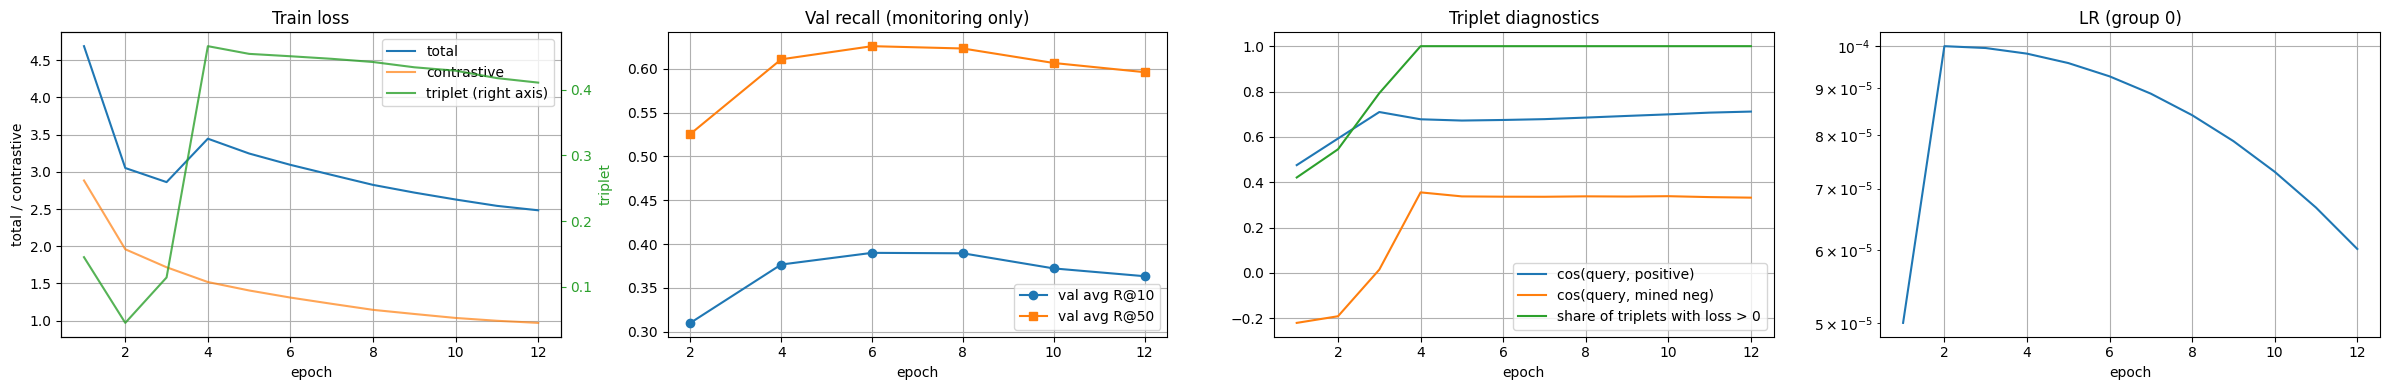

In [16]:
# Cell purpose: Training loop: mine hard negatives, train one epoch, log losses and triplet diagnostics, then on eval epochs score dev (checkpoint + early stopping) and val (monitoring only).

print(f"Training: {cfg.num_epochs} epochs")
print(f"   Category batching + residual query")
print(f"   Target head: trains for {cfg.target_warmup_epochs} epochs, "
      f"then frozen" if cfg.target_warmup_epochs else
      "   Target head: frozen from the start")
print(f"  Batches/epoch: {len(train_loader)}")
print(f"  Effective BS: {cfg.batch_size} × {cfg.grad_accum_steps} = "
      f"{cfg.batch_size * cfg.grad_accum_steps}")
print(f"  Steps: {total_steps}, warmup: {warmup_steps}")
print(f"  Mining: every {cfg.mine_every_n_epochs} epoch, "
      f"fast=True")
print(f"  Early stopping: patience {cfg.early_stop_patience} epochs "
      f"on dev avg R@10" if cfg.early_stop_patience else
      "  Early stopping: off")
print(f"  Log: {log_path}")


for epoch in range(cfg.num_epochs):

    if model.target_trainable and epoch == cfg.target_warmup_epochs:
        # Freeze before mining so the cache uses the final head.
        print(f"  Epoch {epoch+1}: freezing target head after "
              f"{cfg.target_warmup_epochs} epochs of training")
        model.set_target_trainable(False)

    if epoch % cfg.mine_every_n_epochs == 0:
        embed_cache.build(model, mining_gallery_loader, device,
                          id2cat=train_id2cat)
        hard_neg_map = miner.mine(embed_cache, all_triplets)
        torch.cuda.empty_cache()
        gc.collect()
        import psutil
        ram = psutil.virtual_memory()
        print(f"   RAM: {ram.used/1e9:.1f}/{ram.total/1e9:.1f} GB "
              f"({ram.percent}%)")

    model.train()

    epoch_loss = {"total": 0, "contrastive": 0, "triplet": 0}
    # Sums for the triplet diagnostics (all embeddings are L2-normalized,
    # so a dot product is the cosine similarity).
    diag = {"cos_pos": 0.0, "n_q": 0, "cos_neg": 0.0, "n_neg": 0,
            "active": 0}
    cat_counts = {}
    n_batches = 0
    optimizer.zero_grad()

    pbar = tqdm(train_loader,
                desc=f"Epoch {epoch+1}/{cfg.num_epochs}")
    for step, batch in enumerate(pbar):
        ref_px = batch["ref_pixel_values"].to(device)
        tgt_px = batch["target_pixel_values"].to(device)
        texts  = batch["mod_texts"]
        batch_idxs = batch["indices"]

        batch_cat = batch["categories"][0]
        cat_counts[batch_cat] = cat_counts.get(batch_cat, 0) + 1

        ref_rpx = batch.get("ref_resnet_pixels")
        tgt_rpx = batch.get("target_resnet_pixels")
        if ref_rpx is not None:
            ref_rpx = ref_rpx.to(device)
        if tgt_rpx is not None:
            tgt_rpx = tgt_rpx.to(device)

        neg_embeds, neg_mask = get_neg_embeddings_for_batch(
            batch_idxs, hard_neg_map, embed_cache,
            num_negs=cfg.num_neg_per_sample, device=device)

        if cfg.fp16:
            with autocast():
                query_emb  = model.encode_query(ref_px, texts, ref_rpx)
                target_emb = model.encode_positive(tgt_px, tgt_rpx)
            losses = criterion(
                query_emb, target_emb,
                neg_embeds if neg_mask.any() else None,
                neg_mask   if neg_mask.any() else None)
            loss = losses["total"] / cfg.grad_accum_steps

            scaler.scale(loss).backward()
            if (step + 1) % cfg.grad_accum_steps == 0:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    cfg.max_grad_norm)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()
                scheduler.step()
                global_step += 1
        else:
            query_emb  = model.encode_query(ref_px, texts, ref_rpx)
            target_emb = model.encode_positive(tgt_px, tgt_rpx)
            losses = criterion(
                query_emb, target_emb,
                neg_embeds if neg_mask.any() else None,
                neg_mask   if neg_mask.any() else None)
            loss = losses["total"] / cfg.grad_accum_steps
            loss.backward()
            if (step + 1) % cfg.grad_accum_steps == 0:
                nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    cfg.max_grad_norm)
                optimizer.step()
                optimizer.zero_grad()
                scheduler.step()
                global_step += 1

        with torch.no_grad():
            q = query_emb.detach().float()
            cos_p = (q * target_emb.detach().float()).sum(-1)
            diag["cos_pos"] += cos_p.sum().item()
            diag["n_q"] += q.shape[0]
            if neg_mask.any():
                cos_n = torch.einsum("bd,bkd->bk", q, neg_embeds.float())
                # Same hinge as HardNegTripletLoss: d_pos - d_neg + margin.
                hinge = (cos_n - cos_p.unsqueeze(1)) + cfg.triplet_margin
                diag["cos_neg"] += cos_n[neg_mask].sum().item()
                diag["n_neg"] += neg_mask.sum().item()
                diag["active"] += ((hinge > 0) & neg_mask).sum().item()

        for k in epoch_loss:
            epoch_loss[k] += losses[k].item()
        n_batches += 1
        pbar.set_postfix({
            "cat": batch_cat,
            "L": f"{losses['total'].item():.3f}",
            "T": f"{losses['triplet'].item():.3f}",
            "C": f"{losses['contrastive'].item():.3f}",
        })

    if n_batches % cfg.grad_accum_steps != 0:
        if cfg.fp16:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad],
                cfg.max_grad_norm)
            scaler.step(optimizer)
            scaler.update()
        else:
            nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad],
                cfg.max_grad_norm)
            optimizer.step()
        optimizer.zero_grad()
        scheduler.step()
        global_step += 1

    for k in epoch_loss:
        epoch_loss[k] /= max(n_batches, 1)
    history["loss"].append(epoch_loss["total"])
    history["contrastive"].append(epoch_loss["contrastive"])
    history["triplet"].append(epoch_loss["triplet"])
    lr_now = scheduler.get_last_lr()[0]
    history["lr"].append(lr_now)

    cos_pos = diag["cos_pos"] / max(diag["n_q"], 1)
    cos_neg = (diag["cos_neg"] / diag["n_neg"]) if diag["n_neg"] else float("nan")
    active = (diag["active"] / diag["n_neg"]) if diag["n_neg"] else float("nan")
    history["cos_pos"].append(cos_pos)
    history["cos_neg"].append(cos_neg)
    history["active_triplets"].append(active)

    cat_str = " | ".join(f"{c}={n}" for c, n in sorted(cat_counts.items()))
    print(f"  Epoch {epoch+1}/{cfg.num_epochs} | "
          f"loss={epoch_loss['total']:.4f} | "
          f"cont={epoch_loss['contrastive']:.4f} | "
          f"trip={epoch_loss['triplet']:.4f} | lr={lr_now:.2e}")
    print(f"    cos(q,pos)={cos_pos:.4f} | cos(q,neg)={cos_neg:.4f} | "
          f"triplets with loss>0: {100 * active:.1f}% | "
          f"batches: {cat_str}")

    row = {"epoch": epoch + 1, "lr": lr_now,
           "loss": epoch_loss["total"],
           "contrastive": epoch_loss["contrastive"],
           "triplet": epoch_loss["triplet"],
           "cos_pos": cos_pos, "cos_neg": cos_neg,
           "active_triplets": active}

    stop = False
    if (epoch + 1) % cfg.eval_every == 0 or epoch == cfg.num_epochs - 1:
        torch.cuda.empty_cache()
        metrics = evaluate_recall(
            model, dev_loader, dev_gal_loaders, cfg.recall_ks, device)
        print_recall_table(metrics, cfg.categories, cfg.recall_ks,
                           f"DEV epoch {epoch+1} (checkpoint selection), %")

        val_epoch_metrics = evaluate_recall(
            model, val_loader, val_gal_loaders, cfg.recall_ks, device)
        print_recall_table(val_epoch_metrics, cfg.categories, cfg.recall_ks,
                           f"VAL epoch {epoch+1} (monitoring only), %")

        history["R@10"].append(metrics.get("avg_R@10", 0))
        history["R@50"].append(metrics.get("avg_R@50", 0))
        history["val_R@10"].append(val_epoch_metrics.get("avg_R@10", 0))
        history["val_R@50"].append(val_epoch_metrics.get("avg_R@50", 0))
        history["eval_epochs"].append(epoch + 1)
        row.update({f"dev_{k}": v for k, v in metrics.items()})
        row.update({f"val_{k}": v for k, v in val_epoch_metrics.items()})

        val_epoch_rows.extend(
            {"epoch": epoch + 1, **r}
            for r in recall_rows(val_epoch_metrics, cfg.categories,
                                 cfg.recall_ks))
        write_training_log(val_epoch_rows, val_epoch_log_path)

        r10 = metrics.get("avg_R@10", 0)
        if r10 > best_recall:
            best_recall = r10
            best_epoch = epoch + 1
            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "metrics": metrics,
            }, f"{cfg.output_dir}/best_model.pt")
            print(f"     Best dev R@10={100 * r10:.2f} saved!")

        since_best = (epoch + 1) - best_epoch
        if cfg.early_stop_patience and since_best >= cfg.early_stop_patience:
            print(f"  Early stop: dev avg R@10 has not improved for "
                  f"{since_best} epochs (best {100 * best_recall:.2f} "
                  f"at epoch {best_epoch})")
            stop = True

    log_rows.append(row)
    write_training_log(log_rows, log_path)

    if stop:
        break

    if (epoch + 1) % 5 == 0:
        plot_training(history)

    torch.cuda.empty_cache()

epochs_run = epoch + 1
print(f"\n Done after {epochs_run} epochs! Best dev R@10: "
      f"{100 * best_recall:.2f} at epoch {best_epoch}")
plot_training(history)

## Load best checkpoint and report val

Reloads `best_model.pt` (peak **dev** R@10) and scores it on the official val split. This is the reported result. Val was also printed at each eval epoch for monitoring; picking an epoch or changing settings because of those numbers would make val a tuning set again.

In [17]:
# Cell purpose: Reload the best dev checkpoint, score it on val, and save val_results.csv (the reported result).

best_ckpt = torch.load(f"{cfg.output_dir}/best_model.pt",
                        map_location=device,weights_only=False)
model.load_state_dict(best_ckpt["model_state_dict"])
print(f"Loaded best checkpoint (epoch {best_ckpt['epoch']}, "
      f"dev R@10={best_ckpt['metrics'].get('avg_R@10', 0):.4f})")

val_metrics = evaluate_recall(
    model, val_loader, val_gal_loaders, cfg.recall_ks, device
)

print_recall_table(val_metrics, cfg.categories, cfg.recall_ks,
                   f"VAL RESULTS (best dev checkpoint, epoch "
                   f"{best_ckpt['epoch']}), %")
val_log_path = f"{cfg.output_dir}/val_results.csv"
write_training_log(
    recall_rows(val_metrics, cfg.categories, cfg.recall_ks), val_log_path)
print(f"  Saved: {val_log_path}")

Loaded best checkpoint (epoch 8, dev R@10=0.6517)


Gallery dress:   0%|          | 0/30 [00:00<?, ?it/s]

/tmp/ipykernel_568/1114107412.py:21: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Gallery shirt:   0%|          | 0/50 [00:00<?, ?it/s]

Gallery toptee:   0%|          | 0/42 [00:00<?, ?it/s]

Eval:   0%|          | 0/151 [00:00<?, ?it/s]

/tmp/ipykernel_568/1114107412.py:40: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


  VAL RESULTS (best dev checkpoint, epoch 8), %
    category       R@10     R@50
    dress         36.54    60.54
    shirt         37.29    59.81
    toptee        42.99    66.65
    avg           38.94    62.33
  Saved: /content/data/checkpoints/val_results.csv


## Checkpoint I/O

- **`save_checkpoint`** — writes every weight, bias and buffer except the SigLIP parameters that never train (those are reloaded from Hugging Face), plus optimizer, scheduler, metrics, and config. The fine-tuned SigLIP layers are kept. Then saves `final_model.pt`, which holds the **best dev checkpoint's** weights (`weights_epoch`); the optimizer and scheduler state are from the last epoch run.
- **`load_checkpoint`** — loads a checkpoint into a freshly built model and raises an error if any weight other than the skipped frozen SigLIP parameters is missing or unexpected.

In [18]:
# Cell purpose: Define checkpoint save/load helpers and save final_model.pt.

def _frozen_siglip_keys(model):
    """SigLIP parameters that never train; identical to the Hugging Face weights."""
    return {n for n, p in model.named_parameters()
            if n.startswith(("siglip_vision.", "siglip_text."))
            and not p.requires_grad}


def save_checkpoint(model, optimizer, scheduler, epoch, metrics, path,
                    weights_epoch=None):
    skipped = _frozen_siglip_keys(model)
    state = {k: v for k, v in model.state_dict().items() if k not in skipped}
    torch.save({
        "epoch": epoch,
        "weights_epoch": weights_epoch,
        "model_state_dict": state,
        "skipped_frozen_siglip_keys": sorted(skipped),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "metrics": {k: float(v) for k, v in metrics.items()},
        "config": vars(cfg),
    }, path)
    print(f" Saved checkpoint: {path} ({len(state)} tensors; "
          f"{len(skipped)} frozen SigLIP params left to Hugging Face)")


def load_checkpoint(model, path, optimizer=None, scheduler=None):
    ckpt = torch.load(path, map_location="cuda", weights_only=False)
    result = model.load_state_dict(ckpt["model_state_dict"], strict=False)
    expected_missing = set(ckpt.get("skipped_frozen_siglip_keys", []))
    missing = [k for k in result.missing_keys if k not in expected_missing]
    if missing or result.unexpected_keys:
        raise RuntimeError(
            f"Checkpoint does not match the model: {len(missing)} missing "
            f"{missing[:5]}, {len(result.unexpected_keys)} unexpected "
            f"{result.unexpected_keys[:5]}")
    print(f" Loaded {len(ckpt['model_state_dict'])} tensors from {path} "
          f"(weights from epoch {ckpt.get('weights_epoch')})")

    if optimizer and "optimizer_state_dict" in ckpt:
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if scheduler and "scheduler_state_dict" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])

    return ckpt.get("epoch", 0), ckpt.get("metrics", {})


save_checkpoint(
    model, optimizer, scheduler, epochs_run,
    {"best_dev_R@10": best_recall,
     **{f"val_{k}": v for k, v in val_metrics.items()}},
    f"{cfg.output_dir}/final_model.pt",
    weights_epoch=best_ckpt["epoch"],
)

 Saved checkpoint: /content/data/checkpoints/final_model.pt (601 tensors; 727 frozen SigLIP params left to Hugging Face)


## Interactive retrieval

- **`retrieve`** — encode one reference image + modification text, encode a gallery, return top-k `(image_id, similarity)`.
- **`show_retrieval`** — plot the reference and the ranked results.

In [19]:
# Cell purpose: Interactive retrieval: return the top-k gallery images for one reference image and caption, and plot them.

from IPython.display import display
import matplotlib.pyplot as plt
from PIL import Image
import os
@torch.no_grad()
def retrieve(model, processor, ref_image_path, mod_text,
             gallery_loader, resnet_transform=None, top_k=5, device=torch.device("cuda")):
    model.eval()

    img = Image.open(ref_image_path).convert("RGB")
    inputs = processor(images=img, return_tensors="pt")
    ref_px = inputs["pixel_values"].to(device)

    resnet_px = None
    if resnet_transform is not None:
        resnet_px = resnet_transform(img).unsqueeze(0).to(device)

    q = model.encode_query(ref_px, [mod_text], resnet_px)

    all_embs, all_ids = [], []
    for batch in gallery_loader:
        if len(batch) == 3:
            pixels, r_pixels, ids = batch
            r_pixels = r_pixels.to(device)
        else:
            pixels, ids = batch
            r_pixels = None

        all_embs.append(model.encode_target(pixels.to(device), r_pixels).cpu())
        all_ids.extend(ids)
    all_embs = torch.cat(all_embs, 0)

    sims = F.cosine_similarity(q.cpu(), all_embs, dim=-1)
    topk_vals, topk_idx = sims.topk(top_k)

    return [(all_ids[i], topk_vals[j].item()) for j, i in enumerate(topk_idx)]


def show_retrieval(ref_path, mod_text, results, image_dir):
    n = len(results) + 1
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))

    axes[0].imshow(Image.open(ref_path))
    axes[0].set_title(f"Reference\n\"{mod_text}\"", fontsize=9)
    axes[0].axis("off")

    for i, (img_id, score) in enumerate(results):
        for ext in [".jpg", ".png"]:
            p = f"{image_dir}/{img_id}{ext}"
            if os.path.exists(p):
                axes[i+1].imshow(Image.open(p))
                break
        axes[i+1].set_title(f"#{i+1} (sim={score:.3f})\n{img_id}", fontsize=8)
        axes[i+1].axis("off")
    plt.tight_layout()
    plt.show()